Detectron2 and utils setup

In [ ]:
# Install dependencies
#!python -m pip install pyyaml==5.1

# Clone Detectron2 from Facebook Research
!git clone 'https://github.com/facebookresearch/detectron2'

# Install the required dependencies from setup.py
import sys, os, distutils.core
dist = distutils.core.run_setup("./detectron2/setup.py")
!python -m pip install {' '.join([f"'{x}'" for x in dist.install_requires])}

# Add detectron2 to the Python path
sys.path.insert(0, os.path.abspath('./detectron2'))

# Verify installation
import detectron2
print("Detectron2 successfully imported! Version:", detectron2.__version__)

fatal: destination path 'detectron2' already exists and is not an empty directory.
Ignoring dataclasses: markers 'python_version < "3.7"' don't match your environment
Detectron2 successfully imported! Version: 0.6


In [ ]:
# Some basic setup:
# Install opencv-python-headless for image processing
!pip install opencv-python-headless

# Setup detectron2 logger
from detectron2.utils.logger import setup_logger
setup_logger()

# import some common libraries
import cv2
import numpy as np
import os, json, random
from google.colab.patches import cv2_imshow

# import some common detectron2 utilities
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor, DefaultTrainer
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.data.datasets import register_coco_instances
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader

UPLOAD ZIP FILE OF DATA DOWNLOADED FROM ROBOFLOW;
it will be in contents folder

Change the path in the below cell

In [ ]:
!unzip -q "/content/CV Grp 5.v5-onefourth-subset.coco-segmentation.zip"

replace test/18_jpg.rf.f300058cff4ea08ec3d8bc7b2b95575e.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace test/19_jpg.rf.5d32d9202076c5bfb8d79f9888ecd80a.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace test/20_jpg.rf.5353a5e02869844c6dae0ec7f414260a.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace test/21_jpg.rf.170450fd29a1d901e6d930224a2043f2.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace test/22_jpg.rf.52905954e8c7ed2646d79defd21bde81.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace test/23_jpg.rf.2e0c46ef70ce78b69013ad0cfb7c2a12.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace test/25_jpg.rf.58ba10b37f9f32b24c34814673ba225a.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace test/26_jpg.rf.ea272958a5b753ff95d0c61b5b4927d3.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace test/28_jpg.rf.15c3af668b2f0d47fef021457434382b.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace test/2_jpg.rf.d0bc789f54055ba0093b926f23865794.jpg? [y]es, [n]o, [A]ll, [N]one, [r]

Modify the annotations JSON to make 'category_id' 0, THIS IS REQUIRED OTHERWISE NO INFERENCING RUNS, while annotating, category_id was set to 1

In [ ]:
paths = [
    "/content/train/_annotations.coco.json",
    "/content/valid/_annotations.coco.json",
    "/content/test/_annotations.coco.json"
]

# MODIFY CATEGORY ID FOR ANNOTATIONS JSON, Category IDs start from 0, NOT 1.
for path in paths:
    with open(path) as f:
        coco = json.load(f)

    # Fix ALL category_ids: 1 → 0
    for ann in coco["annotations"]:
        ann["category_id"] = 0

    # Fix the categories list
    coco["categories"] = [{"id": 0, "name": "cell"}]

    with open(path, "w") as f:
        json.dump(coco, f, indent=2)

    print("Fixed 'category_id' for:", path)


Fixed 'category_id' for: /content/train/_annotations.coco.json
Fixed 'category_id' for: /content/valid/_annotations.coco.json
Fixed 'category_id' for: /content/test/_annotations.coco.json


Register COCO instances

In [ ]:
DatasetCatalog.clear()
MetadataCatalog.clear()

# Register COCO-format datasets
register_coco_instances(
    "cells_train", {},
    "/content/train/_annotations.coco.json",
    "/content/train"
)
register_coco_instances(
    "cells_val", {},
    "/content/valid/_annotations.coco.json",
    "/content/valid"
)
register_coco_instances(
    "cells_test", {},
    "/content/test/_annotations.coco.json",
    "/content/test"
)

In [ ]:
cells_metadata = MetadataCatalog.get("cells_train")
print("Dataset registered successfully!")

Dataset registered successfully!


Ignore the warnings :)

In [ ]:
# Check
print("Train:", len(DatasetCatalog.get("cells_train")))
print("Valid:", len(DatasetCatalog.get("cells_val")))
print("Test:", len(DatasetCatalog.get("cells_test")))

WARNING [12/05 13:22:45 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[12/05 13:22:45 d2.data.datasets.coco]: Loaded 6 images in COCO format from /content/train/_annotations.coco.json
Train: 6
WARNING [12/05 13:22:45 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[12/05 13:22:45 d2.data.datasets.coco]: Loaded 6 images in COCO format from /content/valid/_annotations.coco.json
Valid: 6
WARNING [12/05 13:22:45 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[12/05 13:22:45 d2.data.datasets.coco]: Loaded 20 images in COCO format from /content/test/_annotations.coco.json
Test: 20


Eg. of ground truth annotations

WARNING [12/05 13:22:47 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[12/05 13:22:47 d2.data.datasets.coco]: Loaded 6 images in COCO format from /content/train/_annotations.coco.json


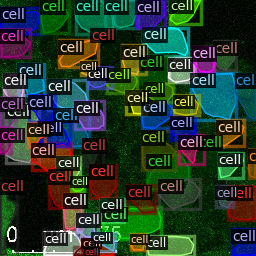

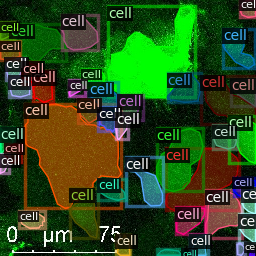

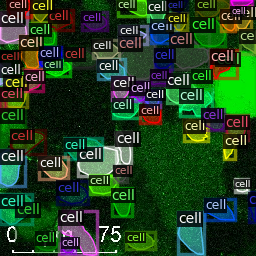

In [ ]:
# eg of GT
dataset_dicts = DatasetCatalog.get("cells_train")

# Visualize 3 random samples
for d in random.sample(dataset_dicts, 3):
    img = cv2.imread(d["file_name"])
    visualizer = Visualizer(img[:, :, ::-1], metadata=cells_metadata, scale=0.5)
    out = visualizer.draw_dataset_dict(d)
    cv2_imshow(out.get_image()[:, :, ::-1])

**Load Pre-trained Mask-RCNN**

In [ ]:
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor

cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(
    "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
))

# COCO pretrained weights (NO training on your data)
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
    "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
)

cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5  # confidence threshold
predictor_pretrained = DefaultPredictor(cfg)

print("Pretrained COCO Mask R-CNN loaded.")

[12/05 13:22:50 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from https://dl.fbaipublicfiles.com/detectron2/COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x/137849600/model_final_f10217.pkl ...
Pretrained COCO Mask R-CNN loaded.


Inferencing the pre-trained Mask-RCNN on our data w/o training it on our data

WARNING [12/05 13:22:52 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[12/05 13:22:52 d2.data.datasets.coco]: Loaded 20 images in COCO format from /content/test/_annotations.coco.json


/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4317.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1205 13:22:53.085000 2305 torch/fx/_symbolic_trace.py:52] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


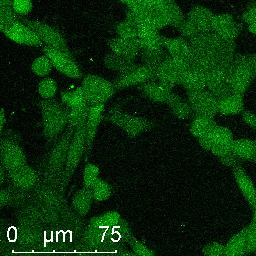

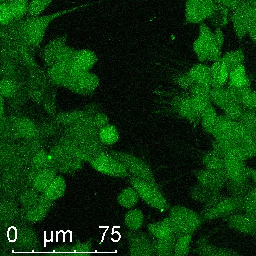

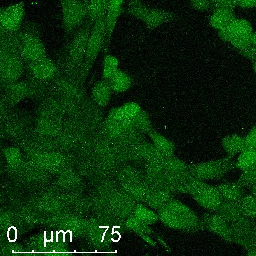

In [ ]:
# USE PRE TRAINED MASK RCNN W/O TRAINING ON OUR DATA
dataset_dicts = DatasetCatalog.get("cells_test")  # or cells_val

for d in random.sample(dataset_dicts, 3):
    img = cv2.imread(d["file_name"])
    outputs = predictor_pretrained(img)

    v = Visualizer(img[:, :, ::-1], scale=0.5)
    v = v.draw_instance_predictions(outputs["instances"].to("cpu"))

    cv2_imshow(v.get_image()[:, :, ::-1])

As expected, it doesnt work

**TRAINING**; set the parameters here

In [ ]:
cfg = get_cfg()
cfg.merge_from_file(
    model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
)

# --- Dataset setup ---
cfg.DATASETS.TRAIN = ("cells_train",)     # training dataset
cfg.DATASETS.TEST = ("cells_val",)        # validation dataset
cfg.DATALOADER.NUM_WORKERS = 2            # number of data loader workers

# --- Initialize from COCO pretrained weights ---
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
    "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
)

# --- Solver (training hyperparameters) ---
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025              # base learning rate
cfg.SOLVER.MAX_ITER = 1000                # max number of iterations, can adjust
cfg.SOLVER.STEPS = []
cfg.SOLVER.CHECKPOINT_PERIOD = 20        # save model every 200 iters, can adjust

# --- Model head settings ---
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1       # ONE class ("cell"), dont change

# --- Output directory ---
cfg.OUTPUT_DIR = "/content/output"
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

# --- Train the model ---
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

[12/05 13:23:01 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}


[12/05 13:23:01 d2.engine.train_loop]: Starting training from iteration 0
[12/05 13:23:09 d2.utils.events]:  eta: 0:05:32  iter: 19  total_loss: 4.989  loss_cls: 0.7935  loss_box_reg: 0.6082  loss_mask: 0.6938  loss_rpn_cls: 2.561  loss_rpn_loc: 0.2851    time: 0.3429  last_time: 0.3796  data_time: 0.0131  last_data_time: 0.0092   lr: 4.9953e-06  max_mem: 2101M
[12/05 13:23:23 d2.utils.events]:  eta: 0:05:25  iter: 39  total_loss: 3.364  loss_cls: 0.7371  loss_box_reg: 0.6095  loss_mask: 0.6899  loss_rpn_cls: 1.017  loss_rpn_loc: 0.2542    time: 0.3464  last_time: 0.3323  data_time: 0.0073  last_data_time: 0.0051   lr: 9.9902e-06  max_mem: 2101M
[12/05 13:23:32 d2.utils.events]:  eta: 0:05:20  iter: 59  total_loss: 2.566  loss_cls: 0.6441  loss_box_reg: 0.6622  loss_mask: 0.6804  loss_rpn_cls: 0.3818  loss_rpn_loc: 0.207    time: 0.3478  last_time: 0.3305  data_time: 0.0065  last_data_time: 0.0059   lr: 1.4985e-05  max_mem: 2105M
[12/05 13:23:40 d2.utils.events]:  eta: 0:05:13  iter: 7

LOSS CURVES with Tensorboard; on right side drag the smoothing slider to 0

In [ ]:
%load_ext tensorboard
%tensorboard --logdir /content/output

<IPython.core.display.Javascript object>

Inferencing on Test samples

[12/05 13:33:01 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_final.pth ...
WARNING [12/05 13:33:02 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[12/05 13:33:02 d2.data.datasets.coco]: Loaded 20 images in COCO format from /content/test/_annotations.coco.json


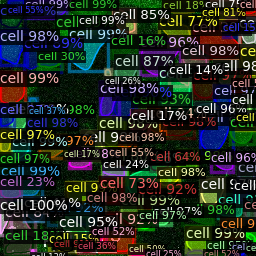

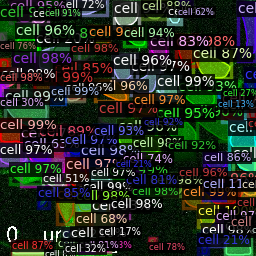

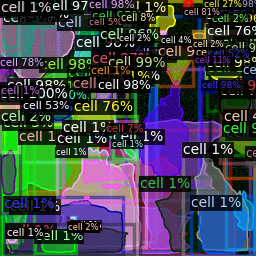

In [ ]:
cfg.MODEL.WEIGHTS = "/content/output/model_final.pth"
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.005
predictor = DefaultPredictor(cfg)

dataset_dicts = DatasetCatalog.get("cells_test")

for d in random.sample(dataset_dicts, 3):
    img = cv2.imread(d["file_name"])
    outputs = predictor(img)

    v = Visualizer(
        img[:, :, ::-1],
        metadata=cells_metadata,
        scale=0.5,
        instance_mode=ColorMode.IMAGE
    )
    out = v.draw_instance_predictions(outputs["instances"].to("cpu"))
    cv2_imshow(out.get_image()[:, :, ::-1])


Inferencing, without 'cell' and % score; ONLY BBOX AND MASK VISIBLE; on final model


[12/05 13:33:08 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_final.pth ...
WARNING [12/05 13:33:09 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[12/05 13:33:09 d2.data.datasets.coco]: Loaded 20 images in COCO format from /content/test/_annotations.coco.json


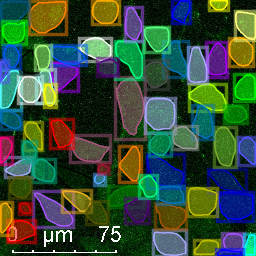

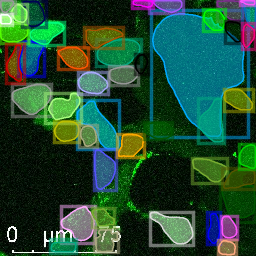

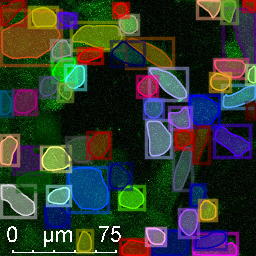

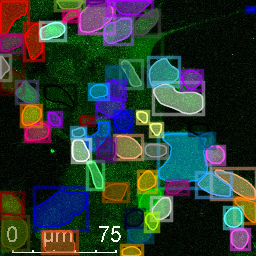

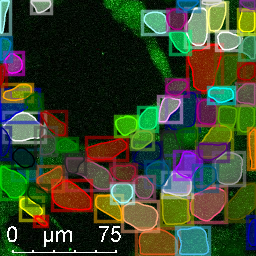

...

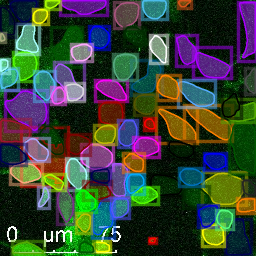

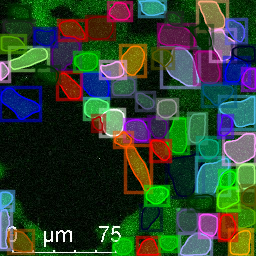

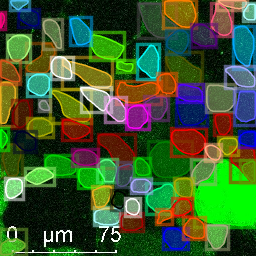

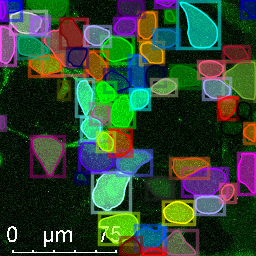

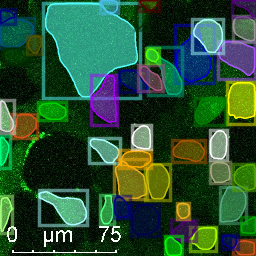

In [ ]:
# Inference + visualize only boxes + masks (no text labels)
# load trained weights & set a low threshold if you want more predictions
cfg.MODEL.WEIGHTS = "/content/output/model_final.pth"
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5   # ADJUST AS NEEDED
predictor = DefaultPredictor(cfg)

test_dataset = DatasetCatalog.get("cells_test")

for d in test_dataset:   # or use random sample to see few sample inferences
    img = cv2.imread(d["file_name"])
    if img is None:
        print("Could not read:", d["file_name"])
        continue

    outputs = predictor(img)
    instances = outputs.get("instances")
    if instances is None or len(instances) == 0:
        print("No predictions for:", d["file_name"])
        # still show the raw image
        cv2_imshow(img[:, :, ::-1])
        continue

    instances = instances.to("cpu")

    # extract boxes and masks if present
    masks = instances.pred_masks if instances.has("pred_masks") else None
    boxes = instances.pred_boxes if instances.has("pred_boxes") else None

    # Create a Visualizer but do NOT pass metadata (or pass None)
    v = Visualizer(img[:, :, ::-1],
                   metadata=None,
                   scale=0.5,
                   instance_mode=ColorMode.IMAGE)  # or IMAGE_BW for gray background

    # overlay_instances draws boxes and masks; labels=None disables text labels
    vis = v.overlay_instances(boxes=boxes, masks=masks, labels=None)
    vis_img = vis.get_image()[:, :, ::-1]

    cv2_imshow(vis_img)


Processing checkpoint: /content/output/model_0000019.pth
[12/05 13:42:23 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000019.pth ...


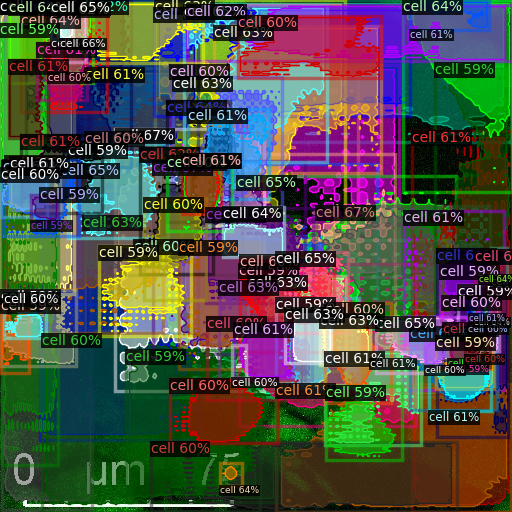

Processing checkpoint: /content/output/model_0000019.pth
[12/05 13:42:28 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000019.pth ...


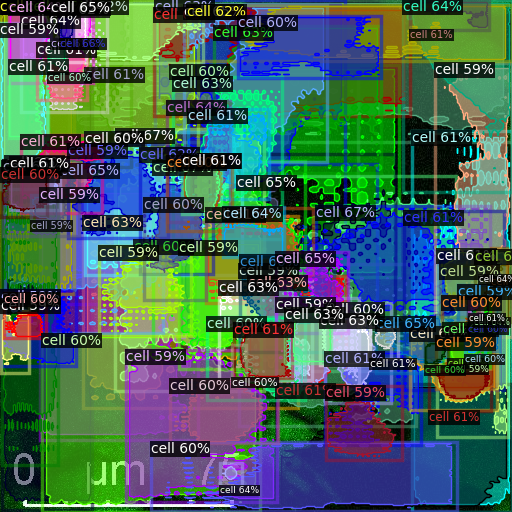

Processing checkpoint: /content/output/model_0000039.pth
[12/05 13:42:34 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000039.pth ...


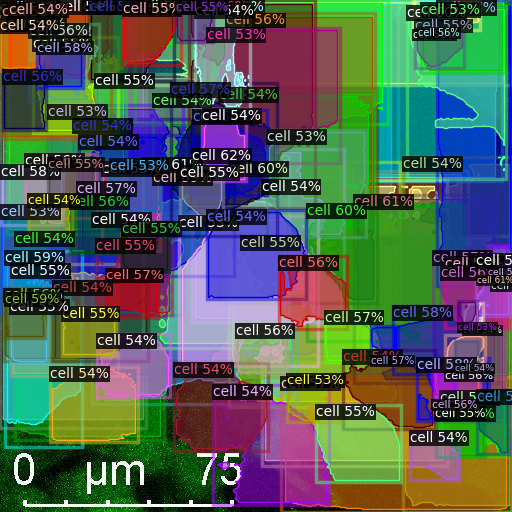

Processing checkpoint: /content/output/model_0000039.pth
[12/05 13:42:37 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000039.pth ...


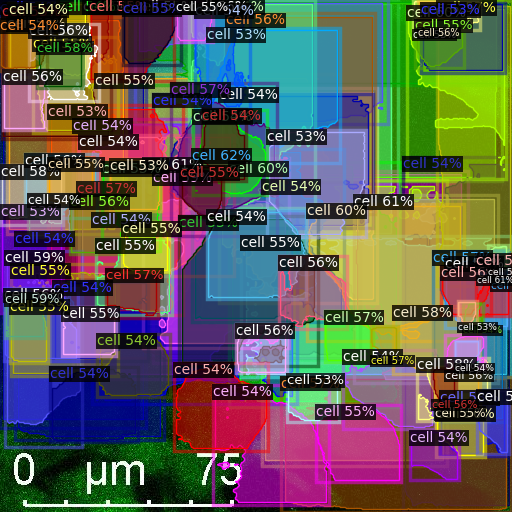

Processing checkpoint: /content/output/model_0000059.pth
[12/05 13:42:40 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000059.pth ...


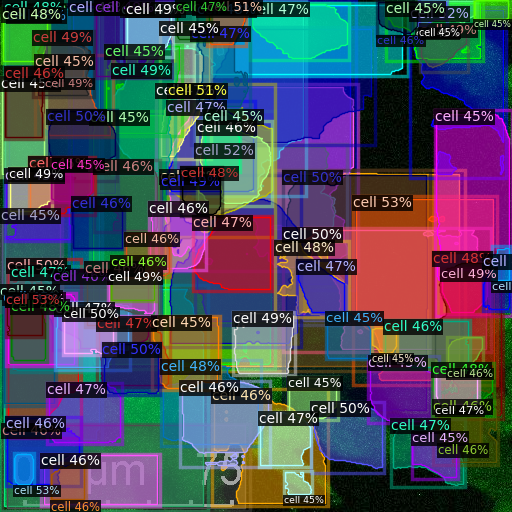

Processing checkpoint: /content/output/model_0000059.pth
[12/05 13:42:44 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000059.pth ...


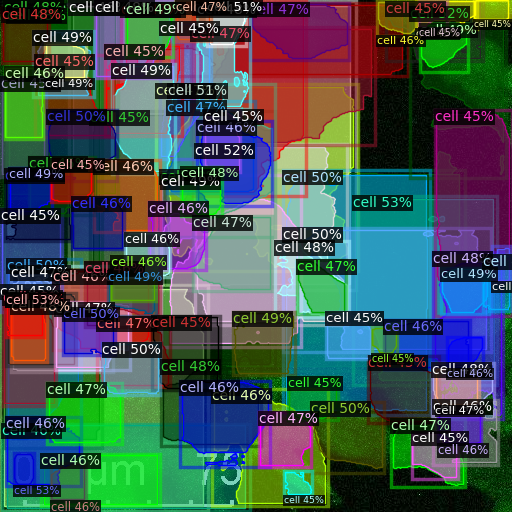

Processing checkpoint: /content/output/model_0000079.pth
[12/05 13:42:47 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000079.pth ...


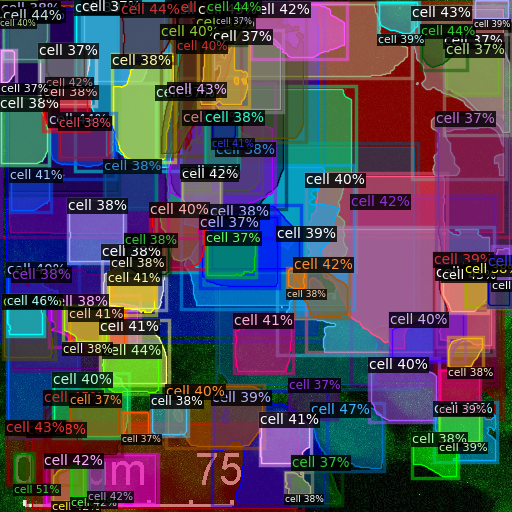

Processing checkpoint: /content/output/model_0000079.pth
[12/05 13:42:50 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000079.pth ...


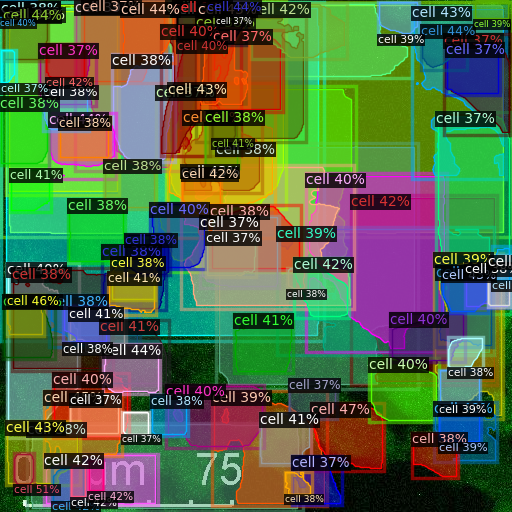

Processing checkpoint: /content/output/model_0000099.pth
[12/05 13:42:52 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000099.pth ...


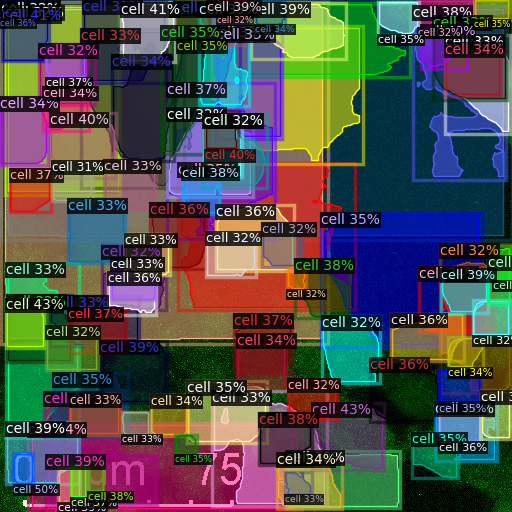

Processing checkpoint: /content/output/model_0000099.pth
[12/05 13:42:56 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000099.pth ...


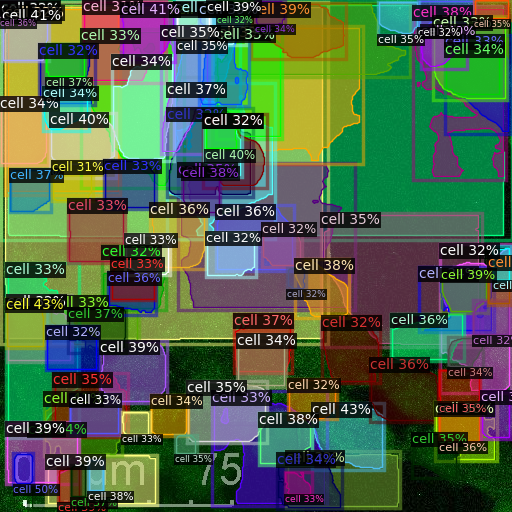

Processing checkpoint: /content/output/model_0000119.pth
[12/05 13:42:59 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000119.pth ...


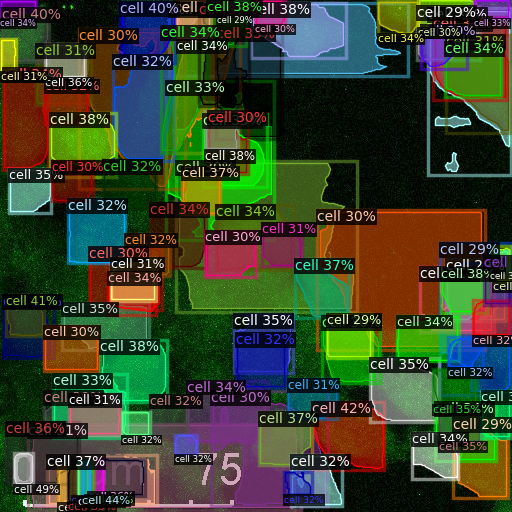

Processing checkpoint: /content/output/model_0000119.pth
[12/05 13:43:02 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000119.pth ...


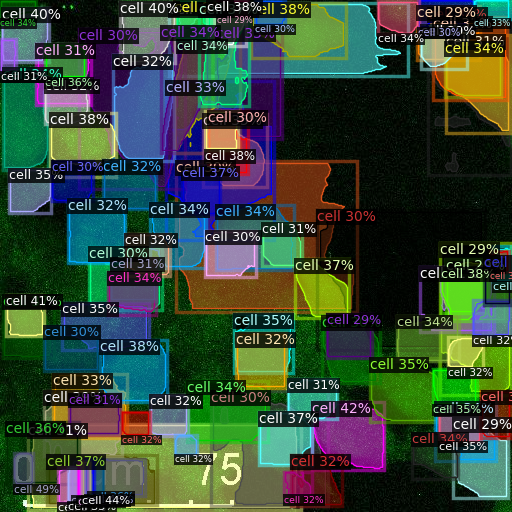

Processing checkpoint: /content/output/model_0000139.pth
[12/05 13:43:04 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000139.pth ...


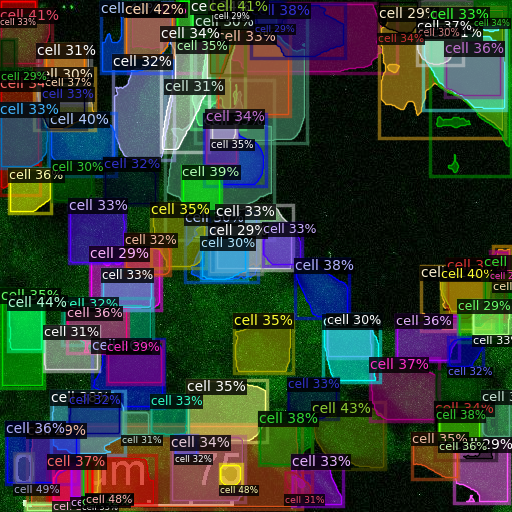

Processing checkpoint: /content/output/model_0000139.pth
[12/05 13:43:08 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000139.pth ...


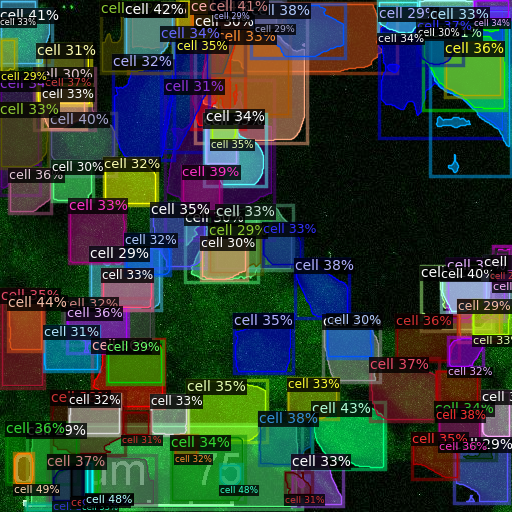

Processing checkpoint: /content/output/model_0000159.pth
[12/05 13:43:11 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000159.pth ...


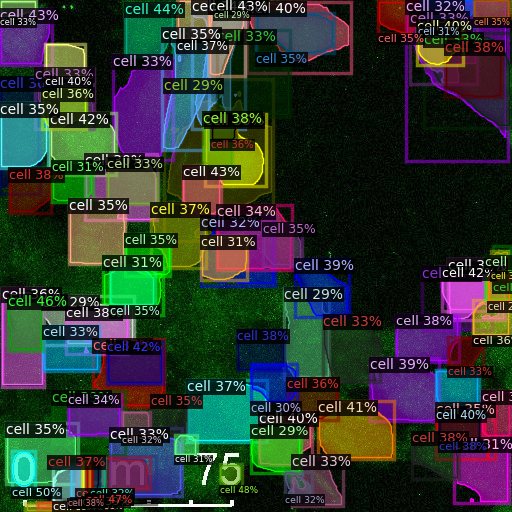

Processing checkpoint: /content/output/model_0000159.pth
[12/05 13:43:14 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000159.pth ...


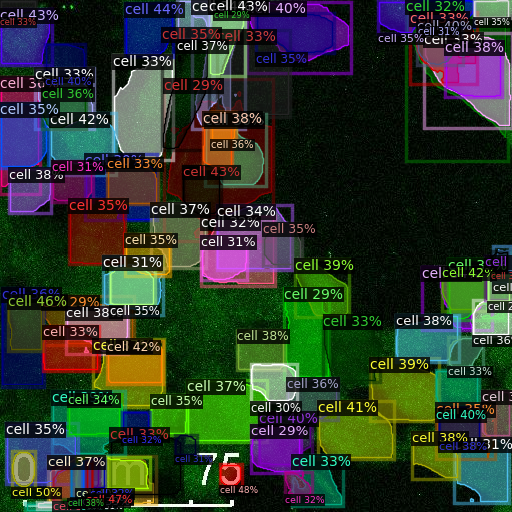

Processing checkpoint: /content/output/model_0000179.pth
[12/05 13:43:16 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000179.pth ...


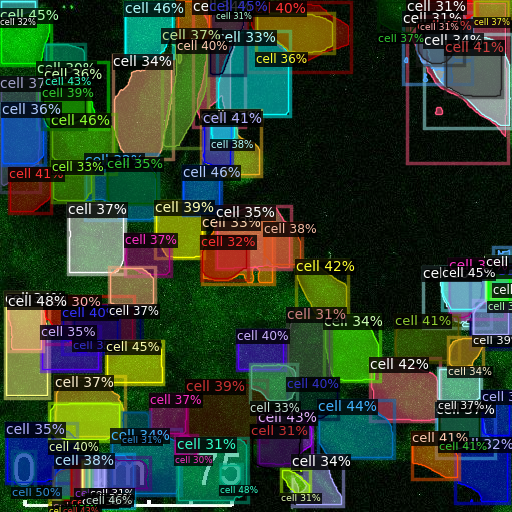

Processing checkpoint: /content/output/model_0000179.pth
[12/05 13:43:20 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000179.pth ...


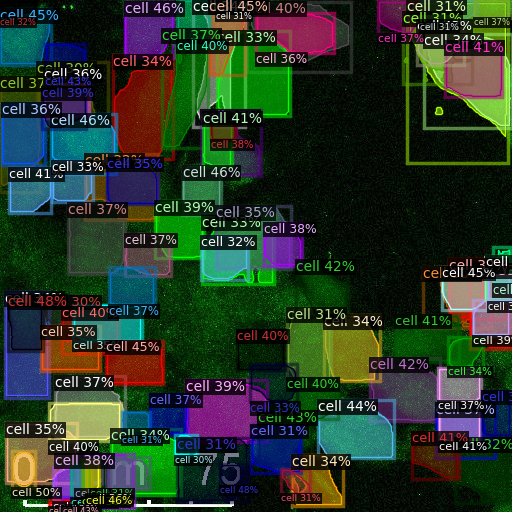

Processing checkpoint: /content/output/model_0000199.pth
[12/05 13:43:22 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000199.pth ...


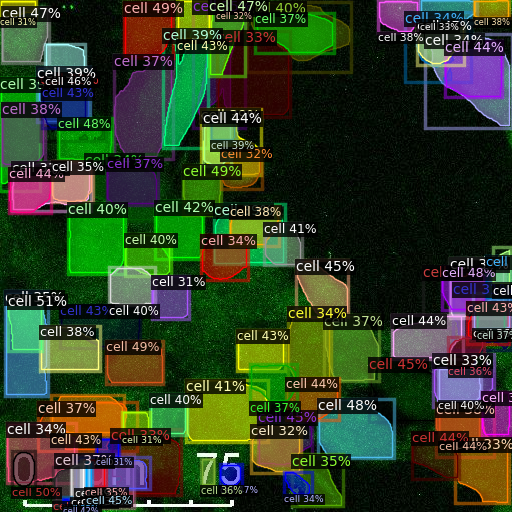

Processing checkpoint: /content/output/model_0000199.pth
[12/05 13:43:25 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000199.pth ...


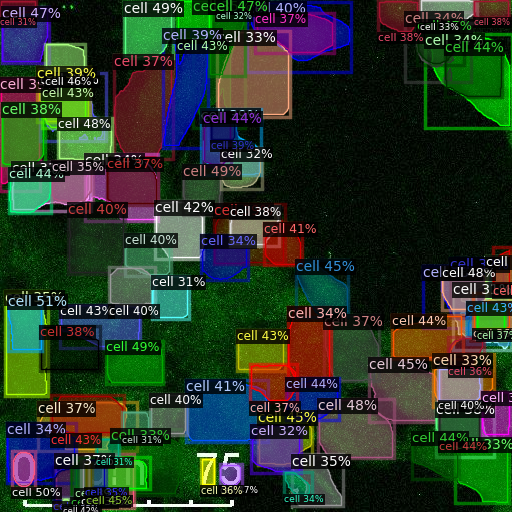

Processing checkpoint: /content/output/model_0000219.pth
[12/05 13:43:28 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000219.pth ...


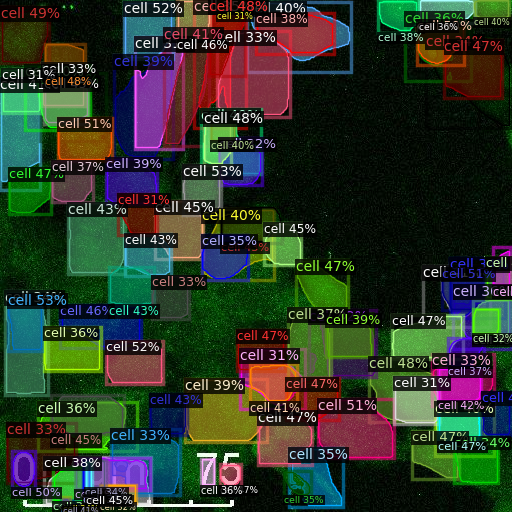

Processing checkpoint: /content/output/model_0000219.pth
[12/05 13:43:31 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000219.pth ...


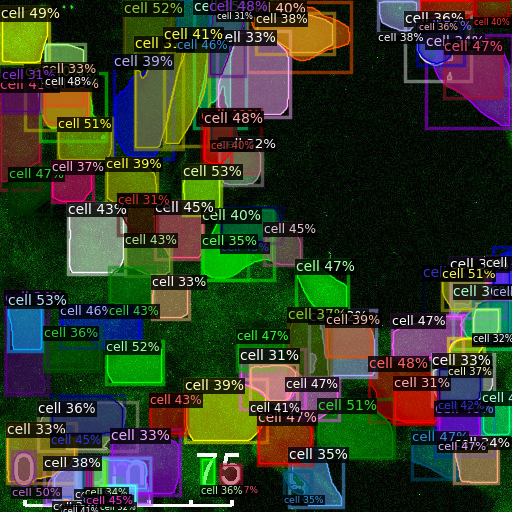

Processing checkpoint: /content/output/model_0000239.pth
[12/05 13:43:34 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000239.pth ...


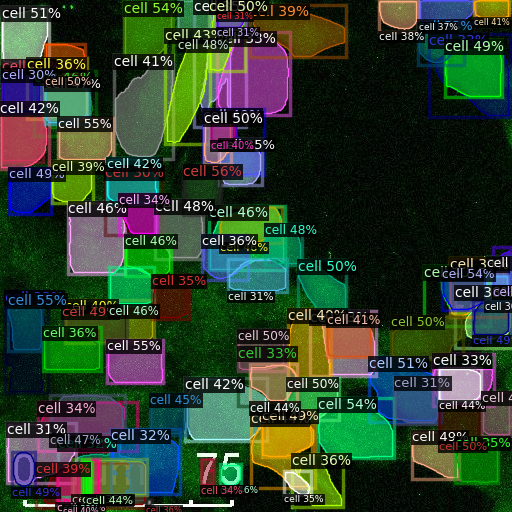

Processing checkpoint: /content/output/model_0000239.pth
[12/05 13:43:37 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000239.pth ...


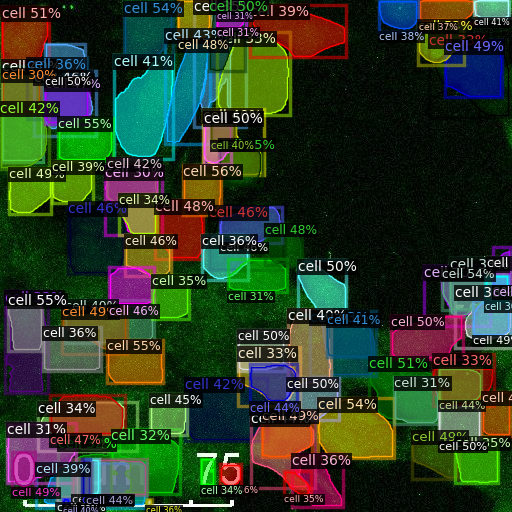

Processing checkpoint: /content/output/model_0000259.pth
[12/05 13:43:40 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000259.pth ...


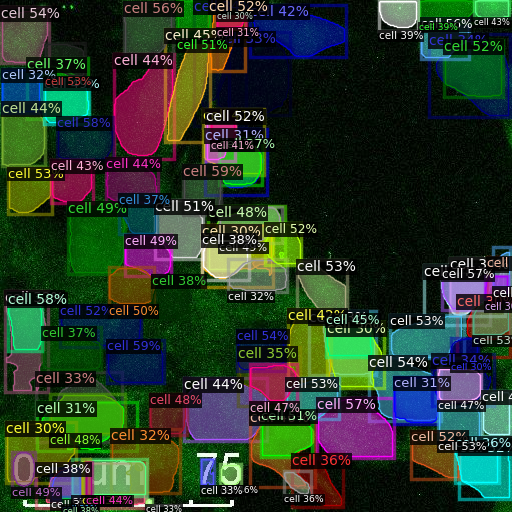

Processing checkpoint: /content/output/model_0000259.pth
[12/05 13:43:43 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000259.pth ...


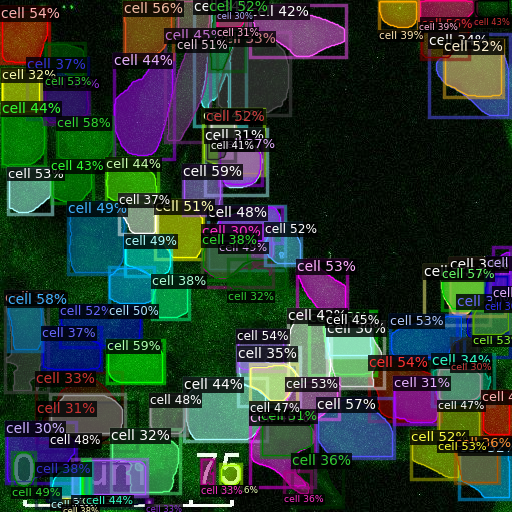

Processing checkpoint: /content/output/model_0000279.pth
[12/05 13:43:45 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000279.pth ...


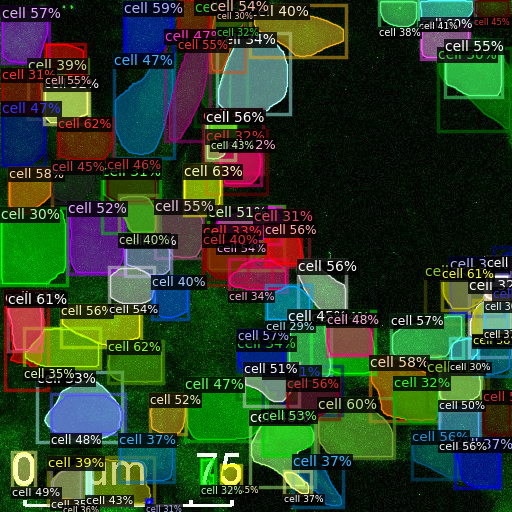

Processing checkpoint: /content/output/model_0000279.pth
[12/05 13:43:49 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000279.pth ...


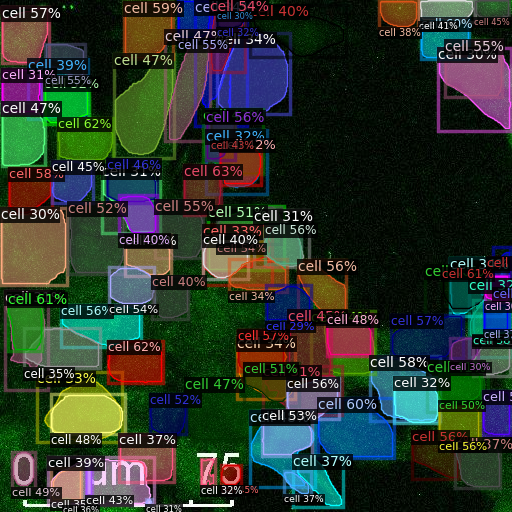

Processing checkpoint: /content/output/model_0000299.pth
[12/05 13:43:51 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000299.pth ...


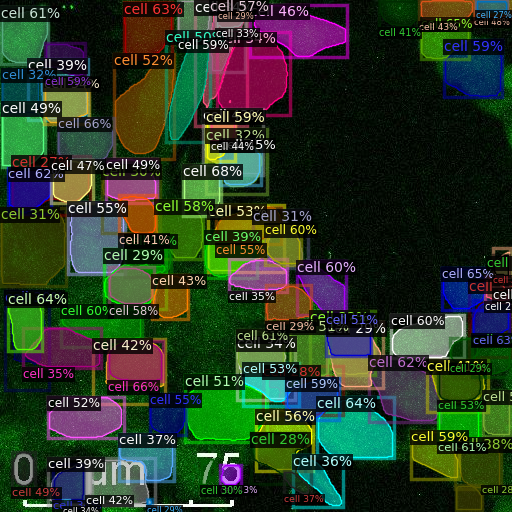

Processing checkpoint: /content/output/model_0000299.pth
[12/05 13:43:54 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000299.pth ...


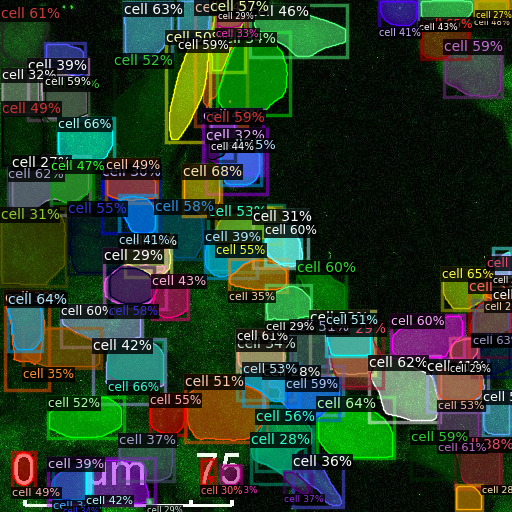

Processing checkpoint: /content/output/model_0000319.pth
[12/05 13:43:57 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000319.pth ...


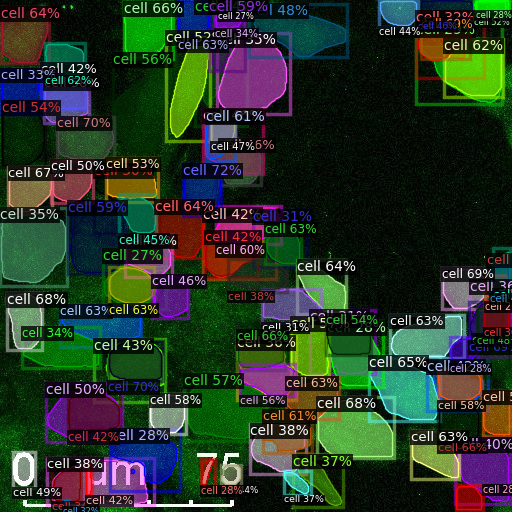

Processing checkpoint: /content/output/model_0000319.pth
[12/05 13:44:01 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000319.pth ...


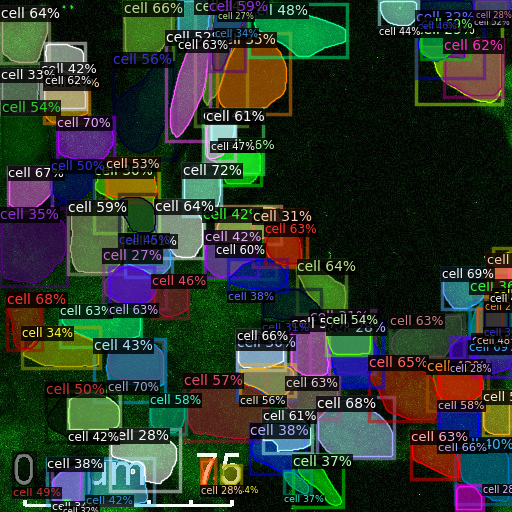

Processing checkpoint: /content/output/model_0000339.pth
[12/05 13:44:03 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000339.pth ...


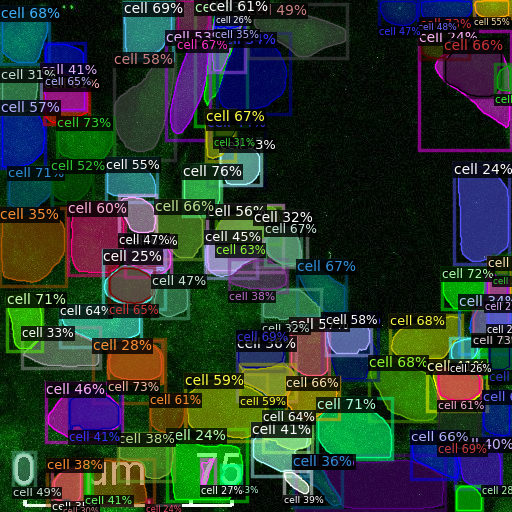

Processing checkpoint: /content/output/model_0000339.pth
[12/05 13:44:06 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000339.pth ...


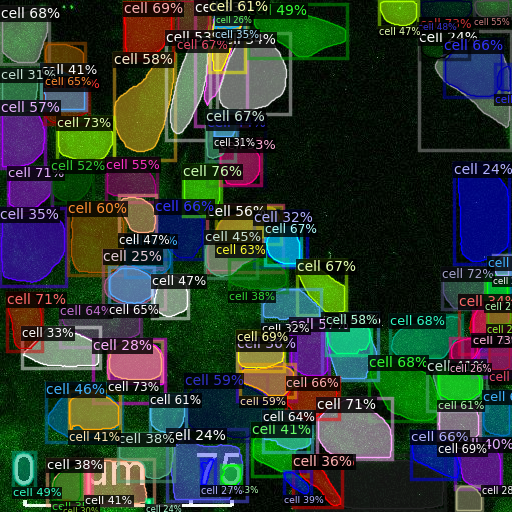

Processing checkpoint: /content/output/model_0000359.pth
[12/05 13:44:08 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000359.pth ...


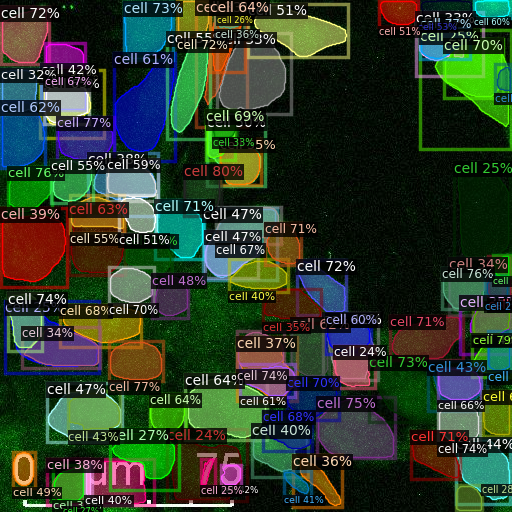

Processing checkpoint: /content/output/model_0000359.pth
[12/05 13:44:12 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000359.pth ...


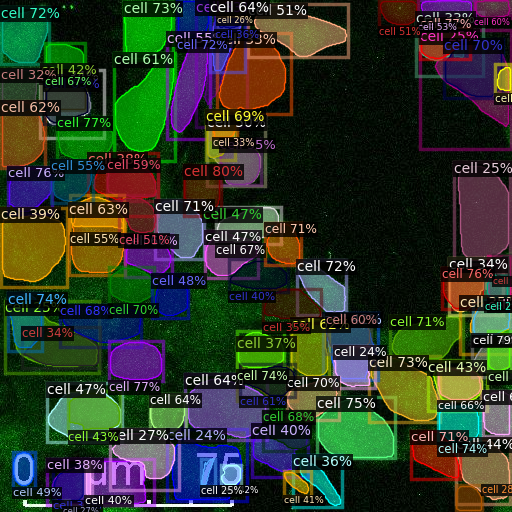

Processing checkpoint: /content/output/model_0000379.pth
[12/05 13:44:15 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000379.pth ...


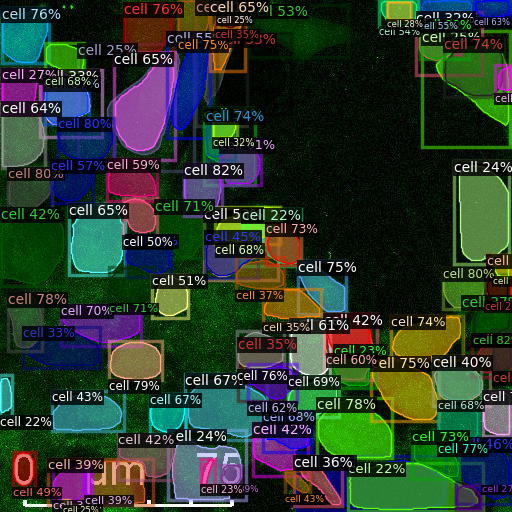

Processing checkpoint: /content/output/model_0000379.pth
[12/05 13:44:18 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000379.pth ...


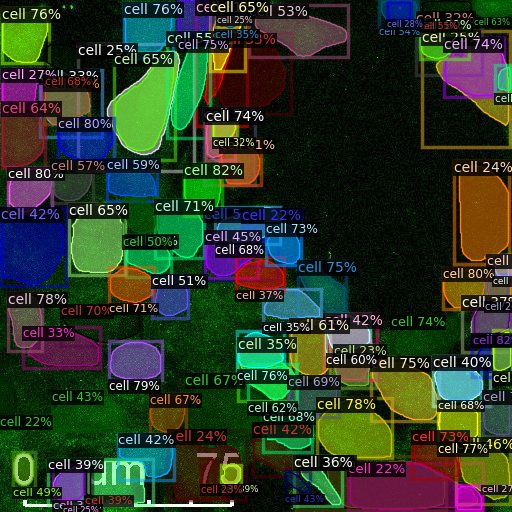

Processing checkpoint: /content/output/model_0000399.pth
[12/05 13:44:20 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000399.pth ...


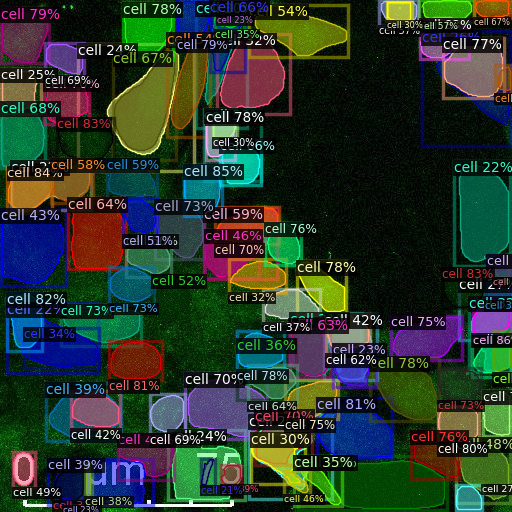

Processing checkpoint: /content/output/model_0000399.pth
[12/05 13:44:25 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000399.pth ...


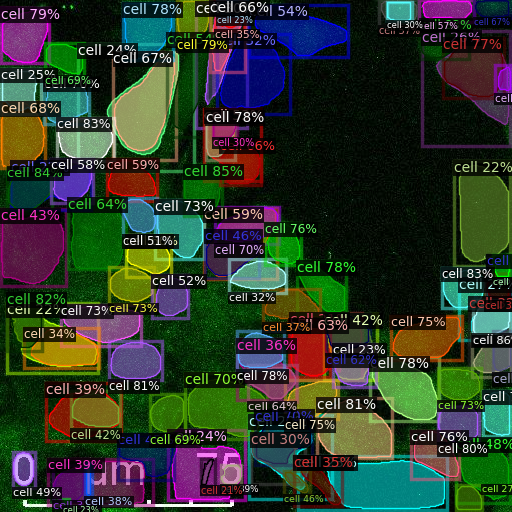

Processing checkpoint: /content/output/model_0000419.pth
[12/05 13:44:27 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000419.pth ...


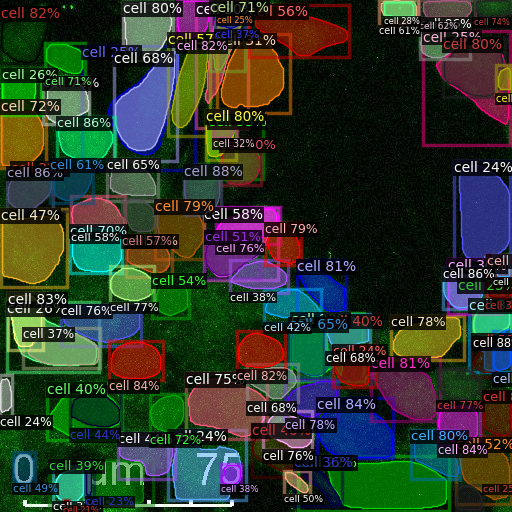

Processing checkpoint: /content/output/model_0000419.pth
[12/05 13:44:30 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000419.pth ...


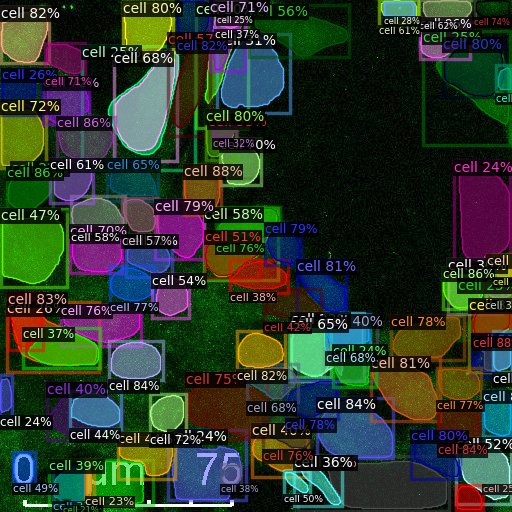

Processing checkpoint: /content/output/model_0000439.pth
[12/05 13:44:33 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000439.pth ...


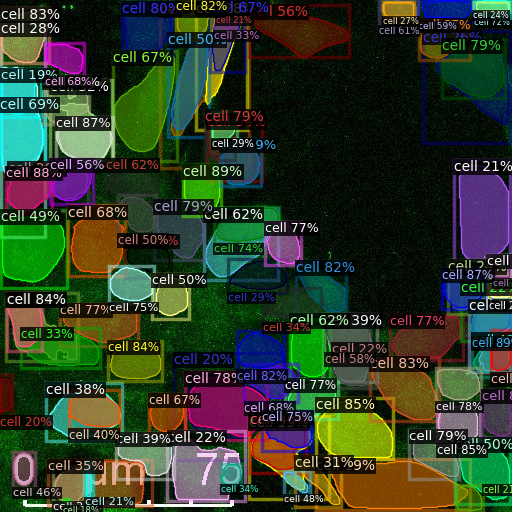

Processing checkpoint: /content/output/model_0000439.pth
[12/05 13:44:37 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000439.pth ...


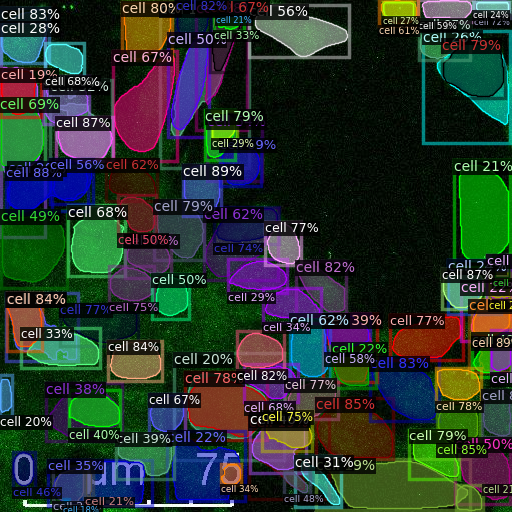

Processing checkpoint: /content/output/model_0000459.pth
[12/05 13:44:39 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000459.pth ...


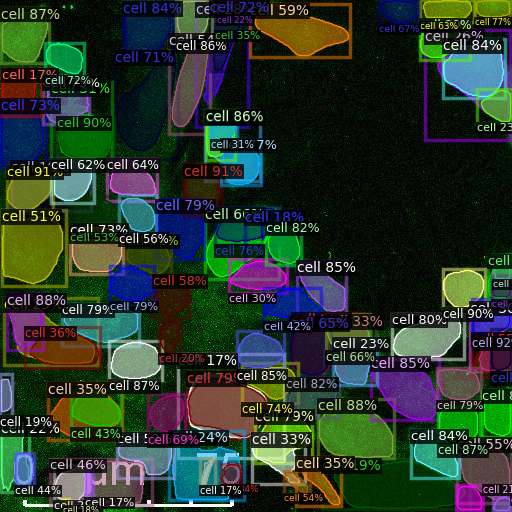

Processing checkpoint: /content/output/model_0000459.pth
[12/05 13:44:43 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000459.pth ...


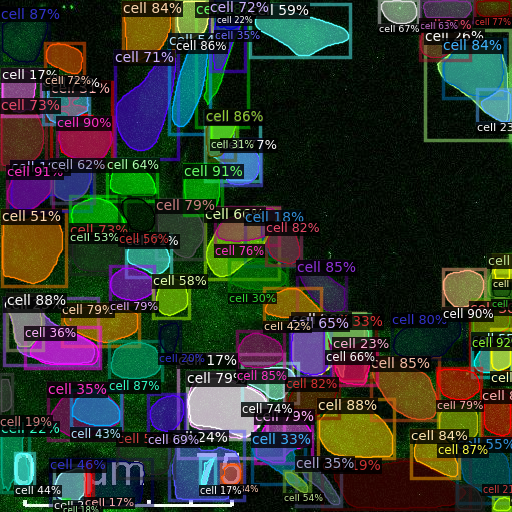

Processing checkpoint: /content/output/model_0000479.pth
[12/05 13:44:45 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000479.pth ...


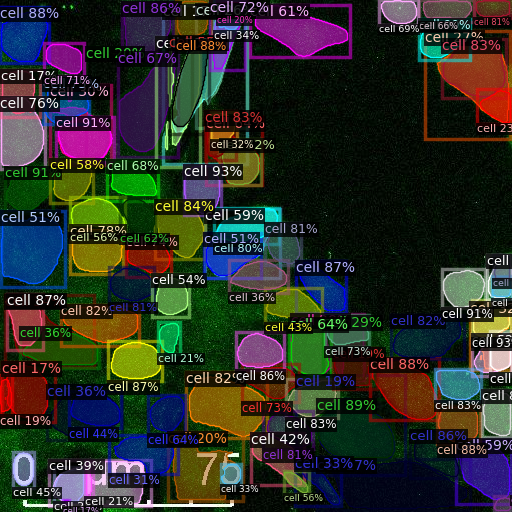

Processing checkpoint: /content/output/model_0000479.pth
[12/05 13:44:49 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000479.pth ...


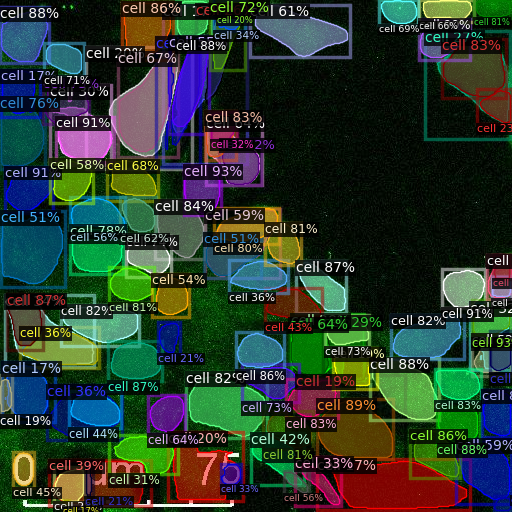

Processing checkpoint: /content/output/model_0000499.pth
[12/05 13:44:52 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000499.pth ...


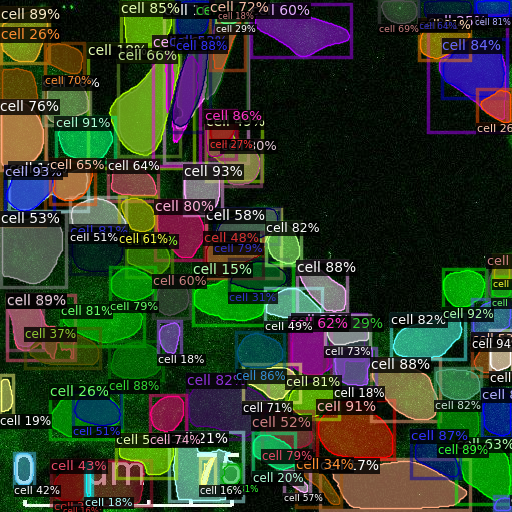

Processing checkpoint: /content/output/model_0000499.pth
[12/05 13:44:55 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000499.pth ...


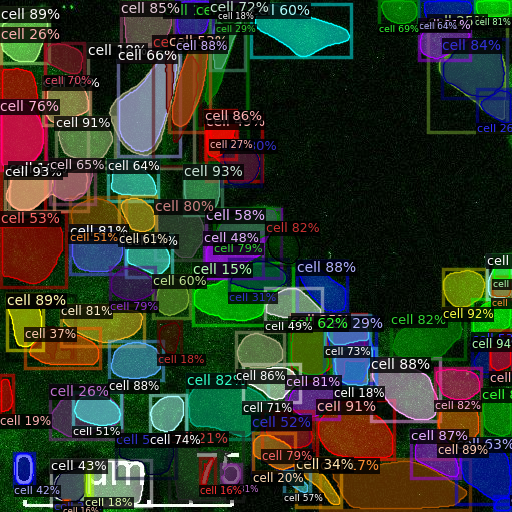

Processing checkpoint: /content/output/model_0000519.pth
[12/05 13:44:58 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000519.pth ...


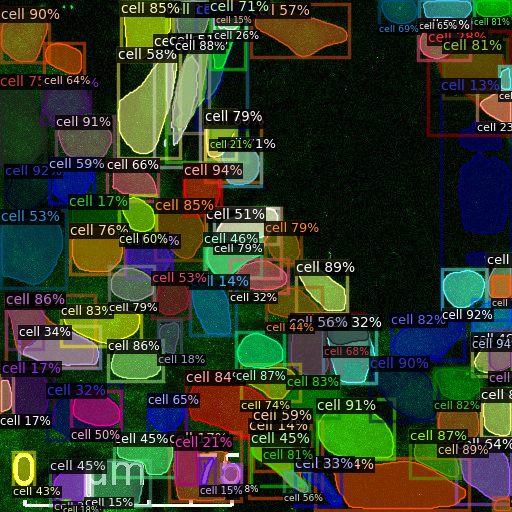

Processing checkpoint: /content/output/model_0000519.pth
[12/05 13:45:01 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000519.pth ...


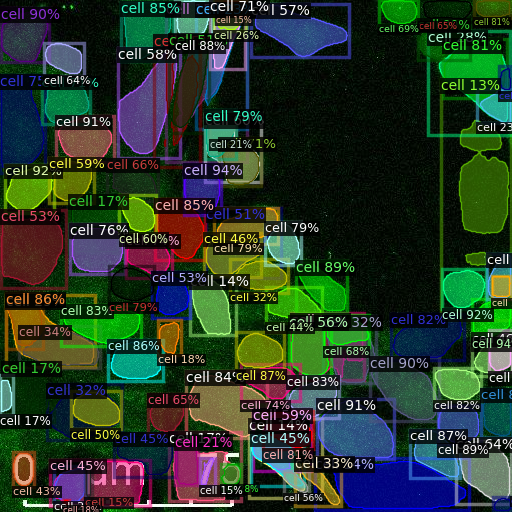

Processing checkpoint: /content/output/model_0000539.pth
[12/05 13:45:04 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000539.pth ...


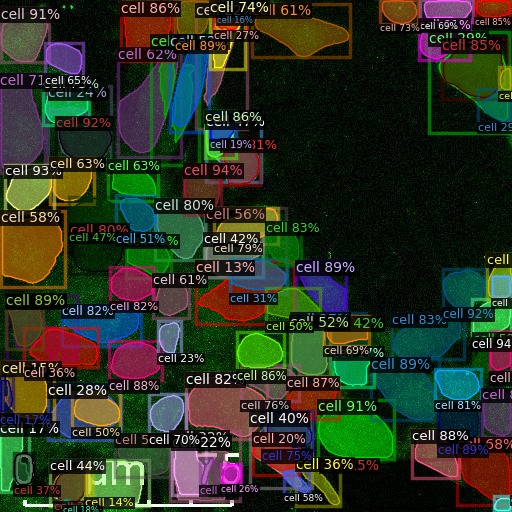

Processing checkpoint: /content/output/model_0000539.pth
[12/05 13:45:07 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000539.pth ...


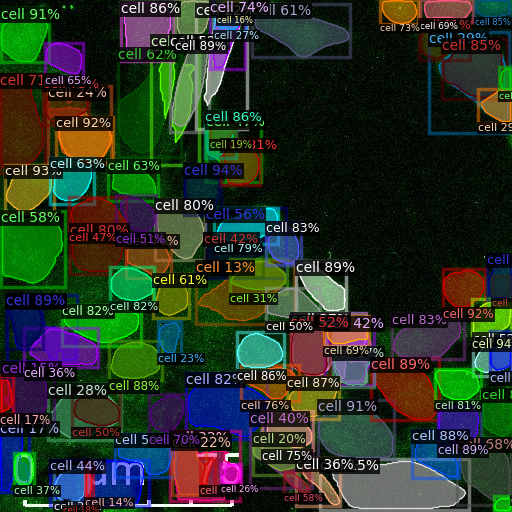

Processing checkpoint: /content/output/model_0000559.pth
[12/05 13:45:10 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000559.pth ...


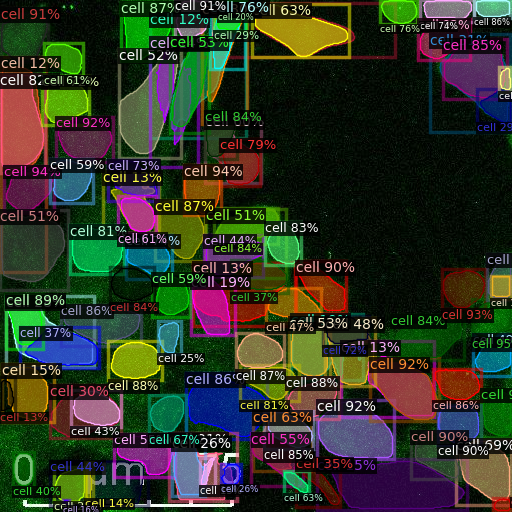

Processing checkpoint: /content/output/model_0000559.pth
[12/05 13:45:13 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000559.pth ...


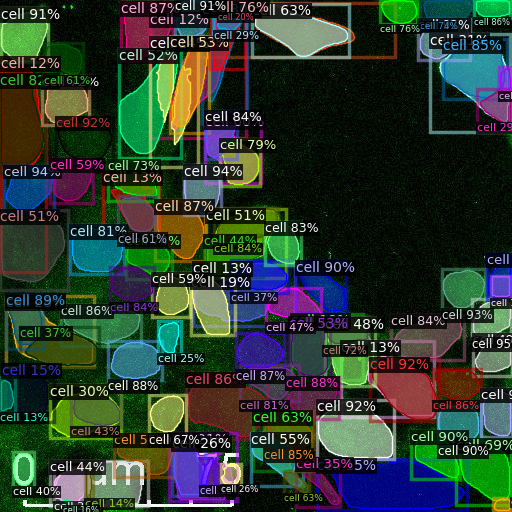

Processing checkpoint: /content/output/model_0000579.pth
[12/05 13:45:16 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000579.pth ...


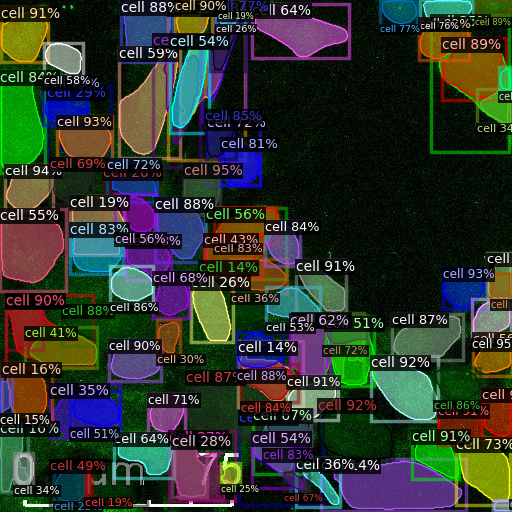

Processing checkpoint: /content/output/model_0000579.pth
[12/05 13:45:20 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000579.pth ...


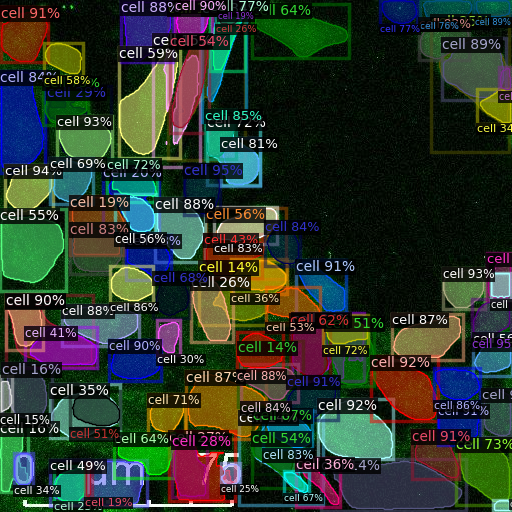

Processing checkpoint: /content/output/model_0000599.pth
[12/05 13:45:23 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000599.pth ...


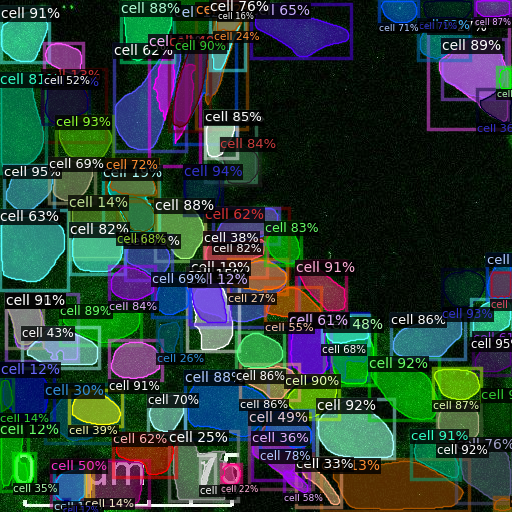

Processing checkpoint: /content/output/model_0000599.pth
[12/05 13:45:26 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000599.pth ...


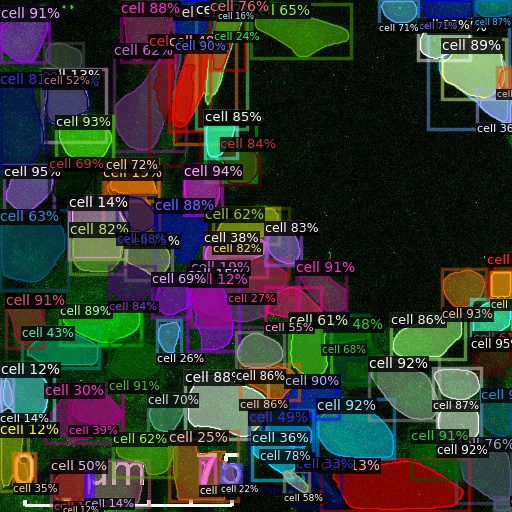

Processing checkpoint: /content/output/model_0000619.pth
[12/05 13:45:28 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000619.pth ...


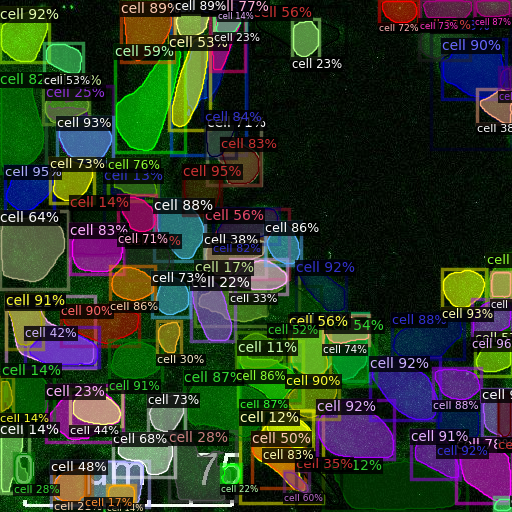

Processing checkpoint: /content/output/model_0000619.pth
[12/05 13:45:32 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000619.pth ...


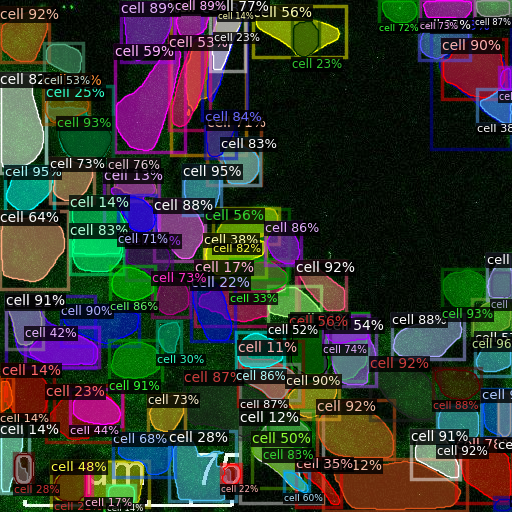

Processing checkpoint: /content/output/model_0000639.pth
[12/05 13:45:35 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000639.pth ...


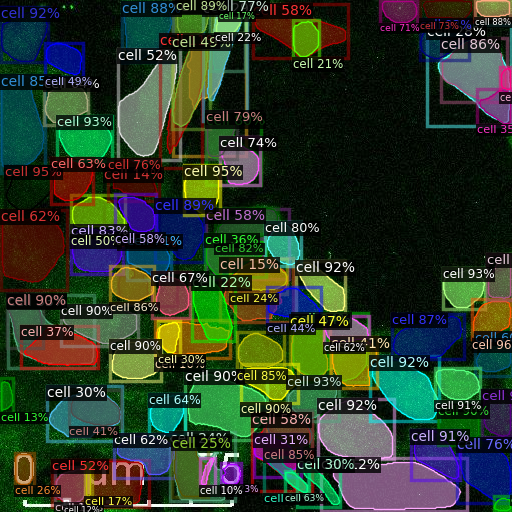

Processing checkpoint: /content/output/model_0000639.pth
[12/05 13:45:38 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000639.pth ...


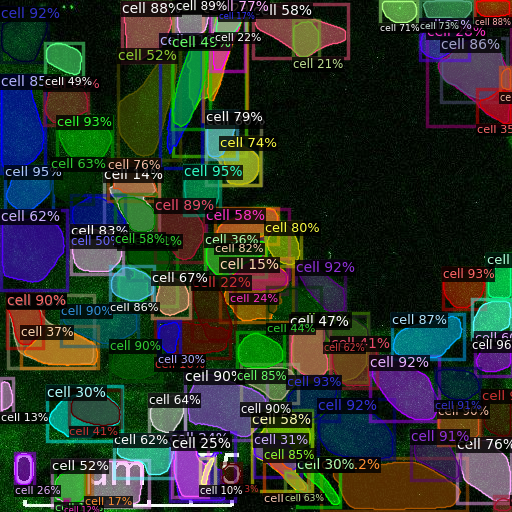

Processing checkpoint: /content/output/model_0000659.pth
[12/05 13:45:40 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000659.pth ...


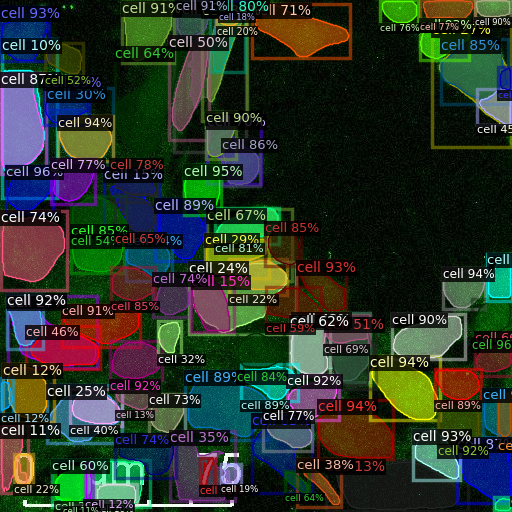

Processing checkpoint: /content/output/model_0000659.pth
[12/05 13:45:44 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000659.pth ...


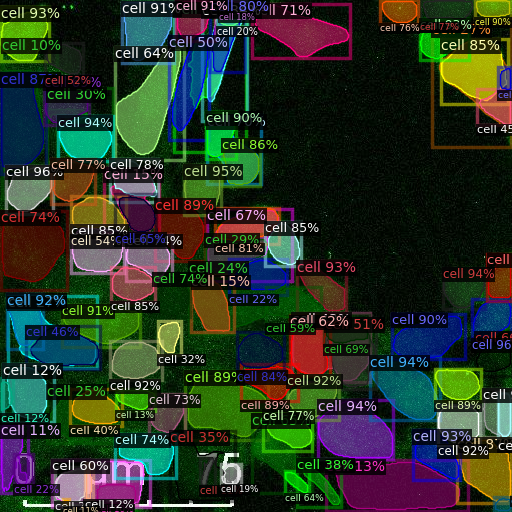

Processing checkpoint: /content/output/model_0000679.pth
[12/05 13:45:46 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000679.pth ...


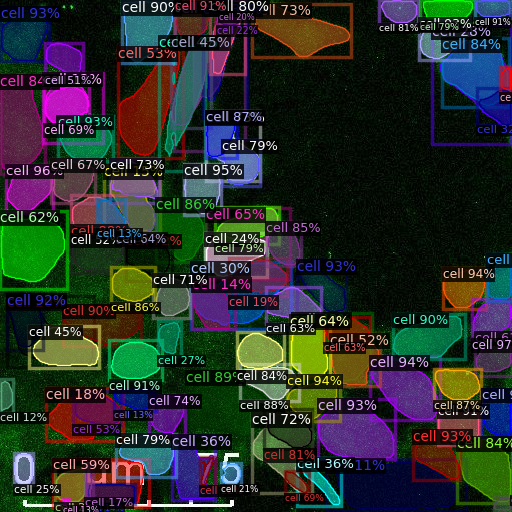

Processing checkpoint: /content/output/model_0000679.pth
[12/05 13:45:49 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000679.pth ...


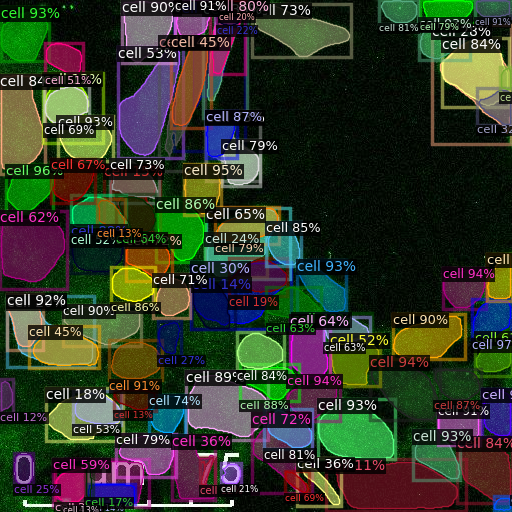

Processing checkpoint: /content/output/model_0000699.pth
[12/05 13:45:51 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000699.pth ...


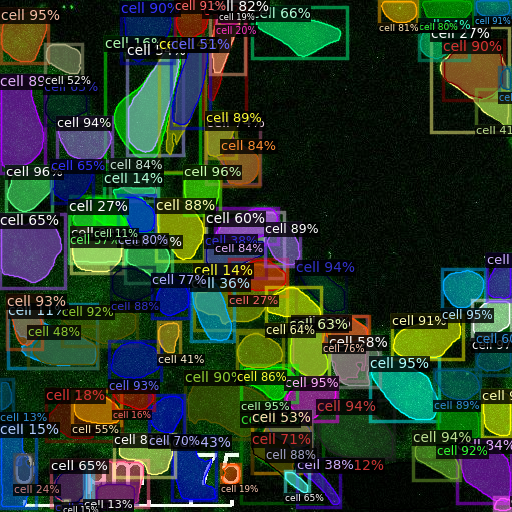

Processing checkpoint: /content/output/model_0000699.pth
[12/05 13:45:54 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000699.pth ...


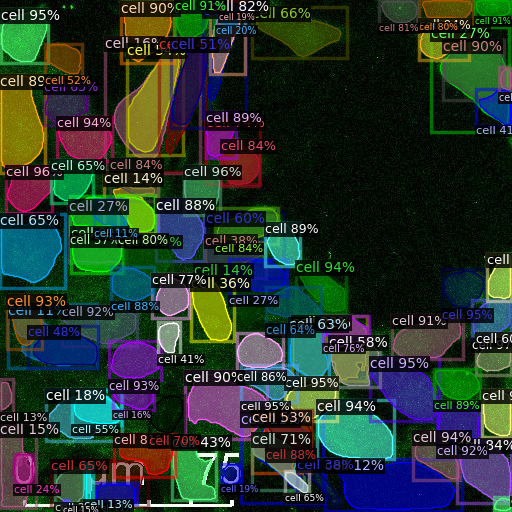

Processing checkpoint: /content/output/model_0000719.pth
[12/05 13:45:56 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000719.pth ...


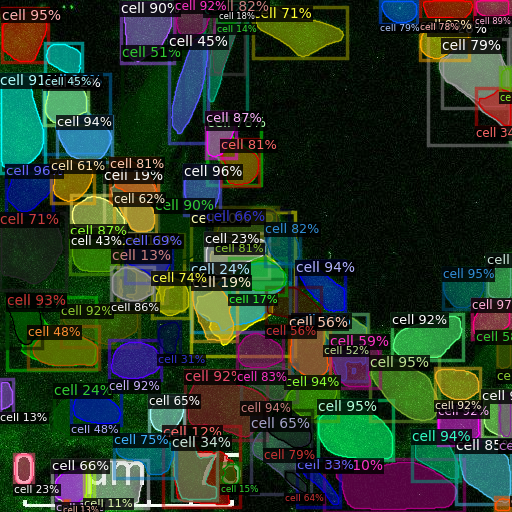

Processing checkpoint: /content/output/model_0000719.pth
[12/05 13:45:59 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000719.pth ...


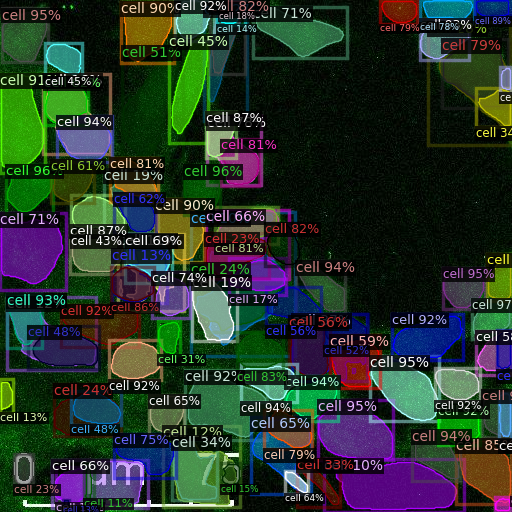

Processing checkpoint: /content/output/model_0000739.pth
[12/05 13:46:01 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000739.pth ...


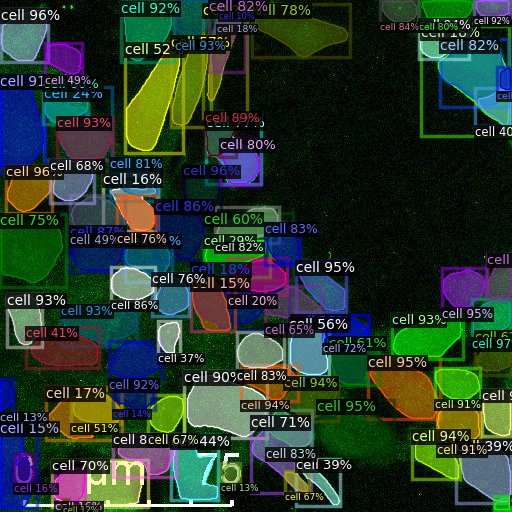

Processing checkpoint: /content/output/model_0000739.pth
[12/05 13:46:04 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000739.pth ...


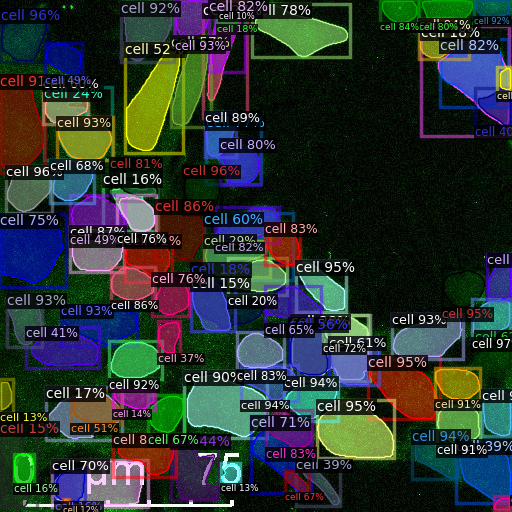

Processing checkpoint: /content/output/model_0000759.pth
[12/05 13:46:06 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000759.pth ...


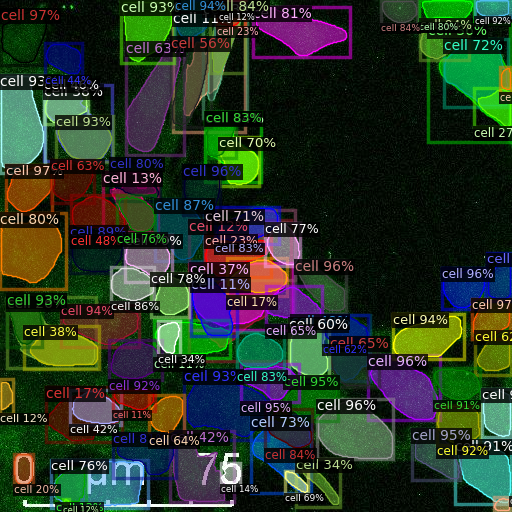

Processing checkpoint: /content/output/model_0000759.pth
[12/05 13:46:09 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000759.pth ...


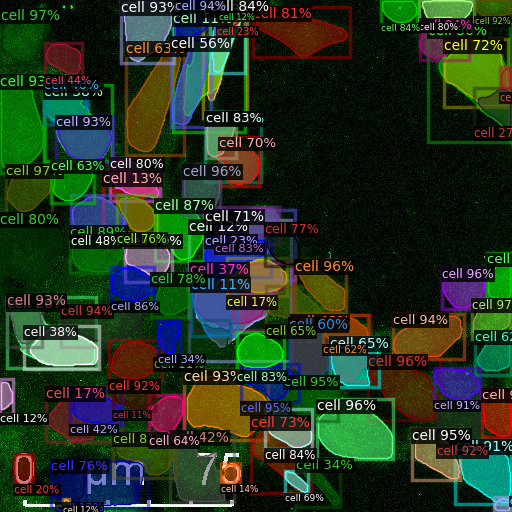

Processing checkpoint: /content/output/model_0000779.pth
[12/05 13:46:11 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000779.pth ...


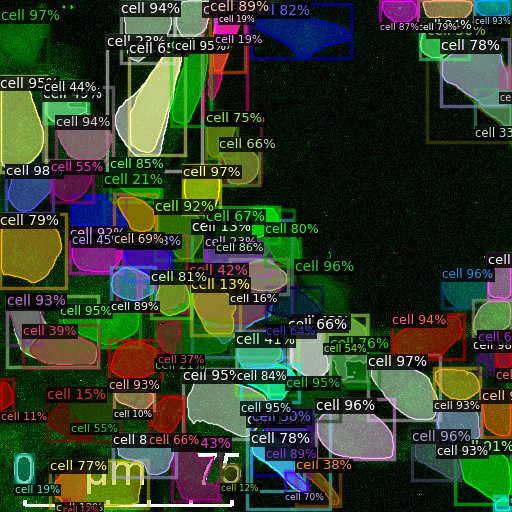

Processing checkpoint: /content/output/model_0000779.pth
[12/05 13:46:14 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000779.pth ...


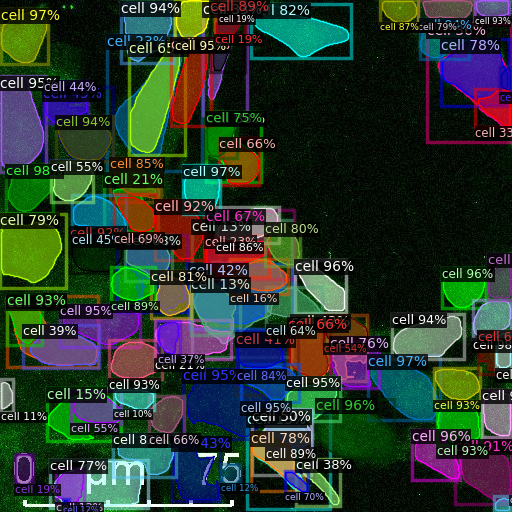

Processing checkpoint: /content/output/model_0000799.pth
[12/05 13:46:16 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000799.pth ...


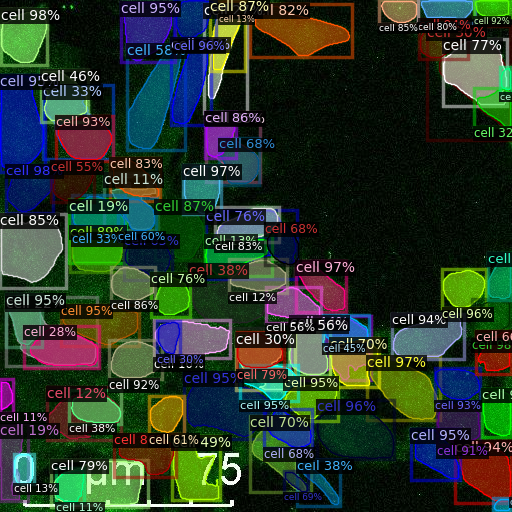

Processing checkpoint: /content/output/model_0000799.pth
[12/05 13:46:20 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000799.pth ...


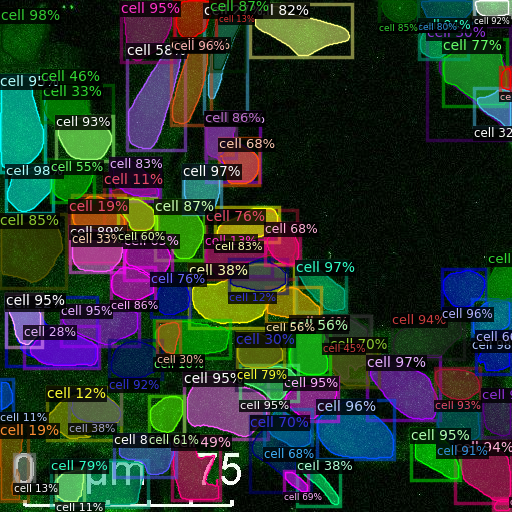

Processing checkpoint: /content/output/model_0000819.pth
[12/05 13:46:22 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000819.pth ...


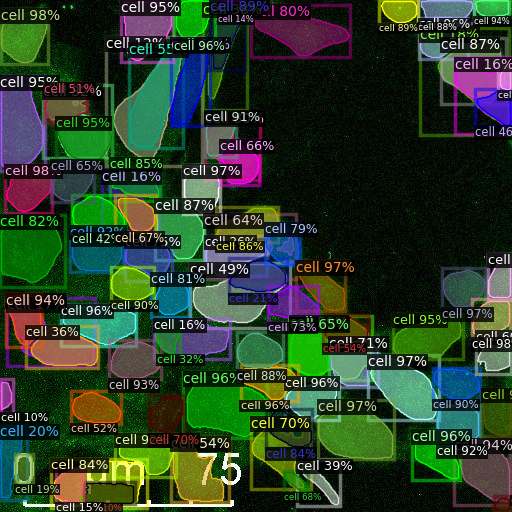

Processing checkpoint: /content/output/model_0000819.pth
[12/05 13:46:25 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000819.pth ...


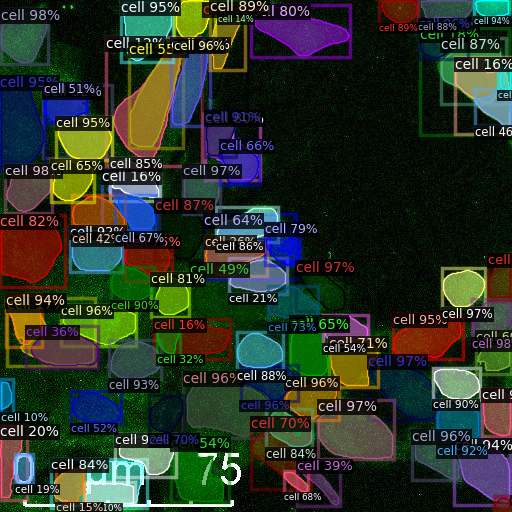

Processing checkpoint: /content/output/model_0000839.pth
[12/05 13:46:26 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000839.pth ...


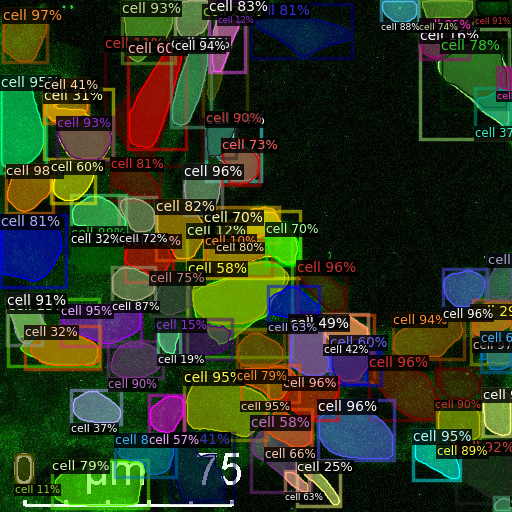

Processing checkpoint: /content/output/model_0000839.pth
[12/05 13:46:29 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000839.pth ...


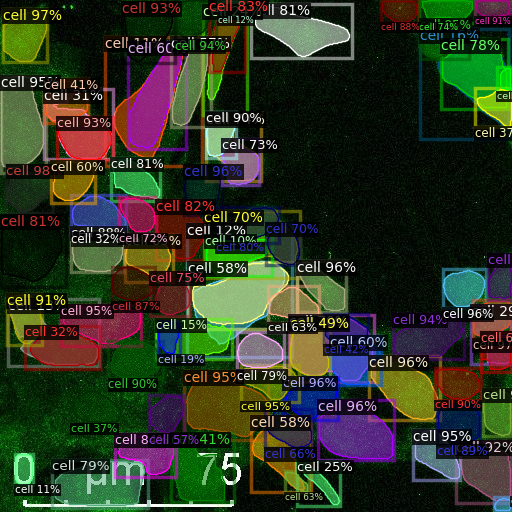

Processing checkpoint: /content/output/model_0000859.pth
[12/05 13:46:31 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000859.pth ...


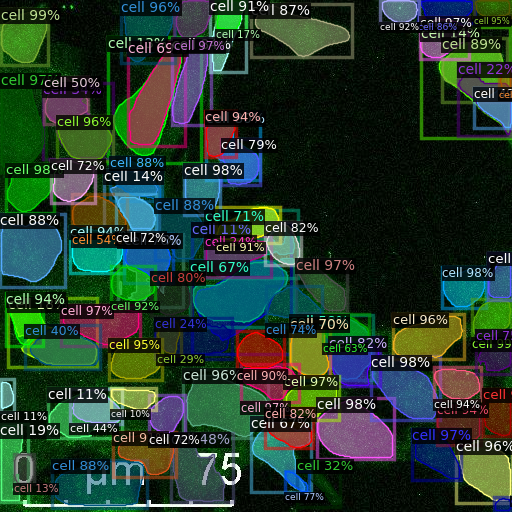

Processing checkpoint: /content/output/model_0000859.pth
[12/05 13:46:35 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000859.pth ...


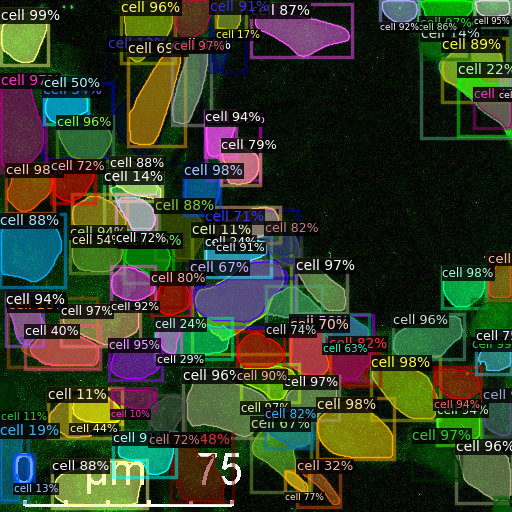

Processing checkpoint: /content/output/model_0000879.pth
[12/05 13:46:36 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000879.pth ...


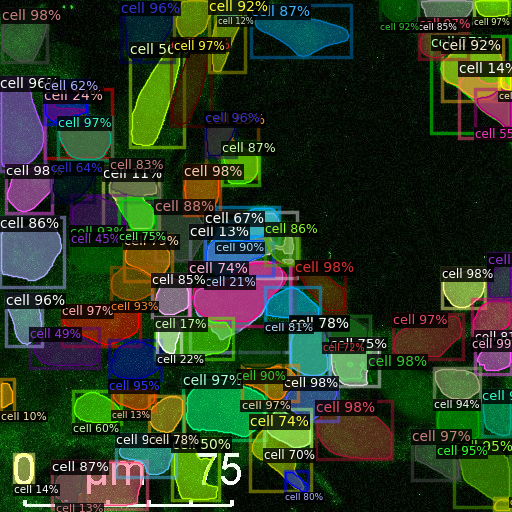

Processing checkpoint: /content/output/model_0000879.pth
[12/05 13:46:39 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000879.pth ...


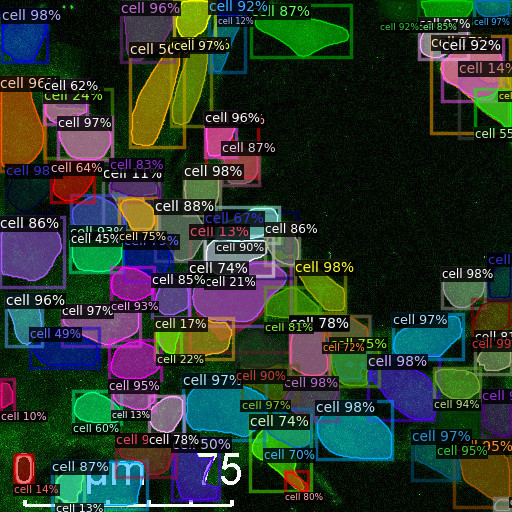

Processing checkpoint: /content/output/model_0000899.pth
[12/05 13:46:41 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000899.pth ...


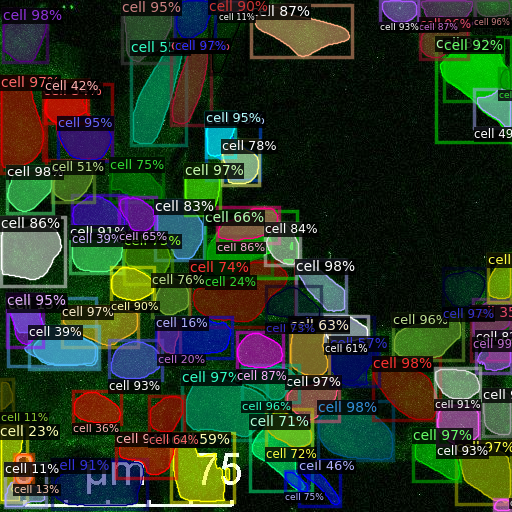

Processing checkpoint: /content/output/model_0000899.pth
[12/05 13:46:45 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000899.pth ...


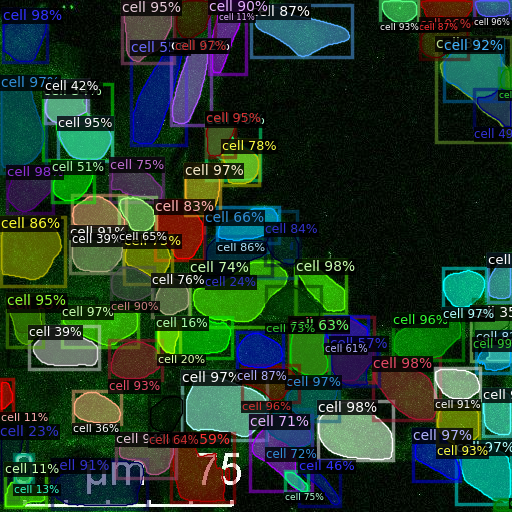

Processing checkpoint: /content/output/model_0000919.pth
[12/05 13:46:46 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000919.pth ...


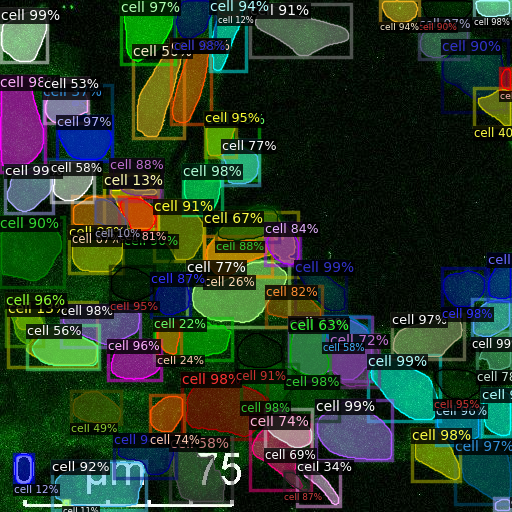

Processing checkpoint: /content/output/model_0000919.pth
[12/05 13:46:49 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000919.pth ...


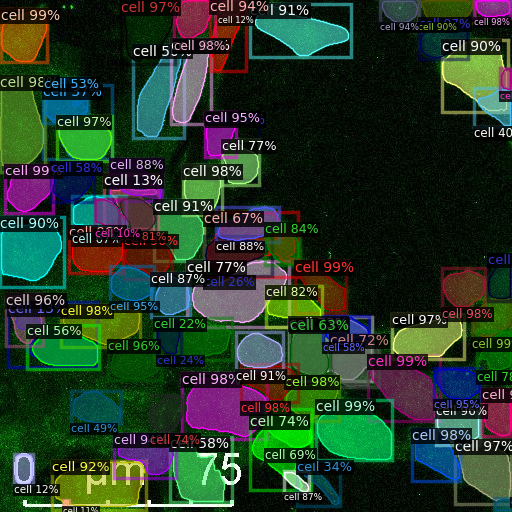

Processing checkpoint: /content/output/model_0000939.pth
[12/05 13:46:51 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000939.pth ...


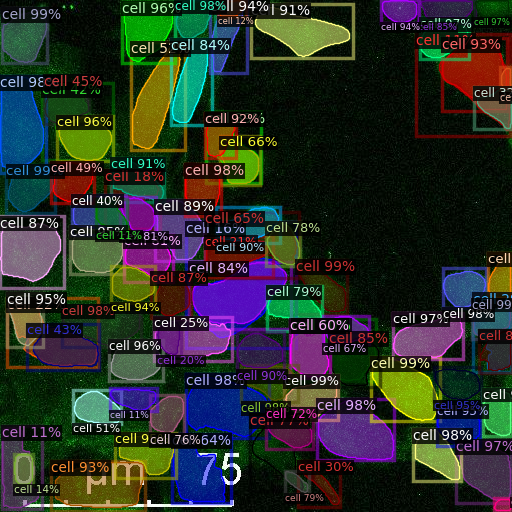

Processing checkpoint: /content/output/model_0000939.pth
[12/05 13:46:54 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000939.pth ...


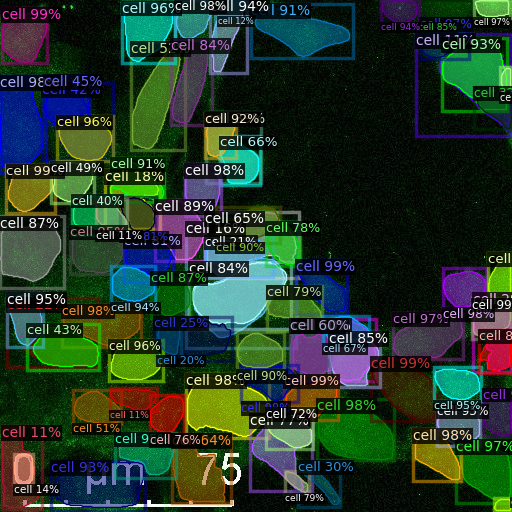

Processing checkpoint: /content/output/model_0000959.pth
[12/05 13:46:56 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000959.pth ...


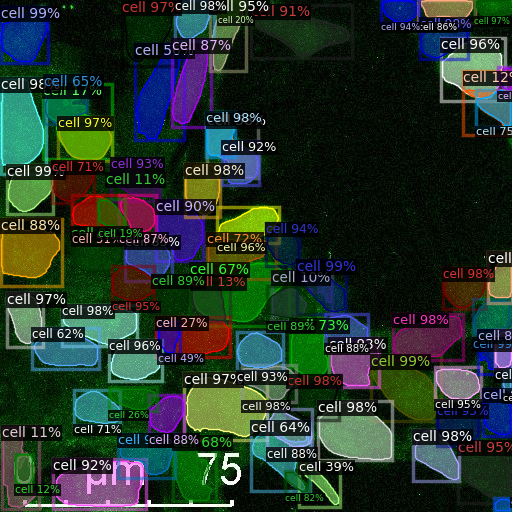

Processing checkpoint: /content/output/model_0000959.pth
[12/05 13:46:59 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000959.pth ...


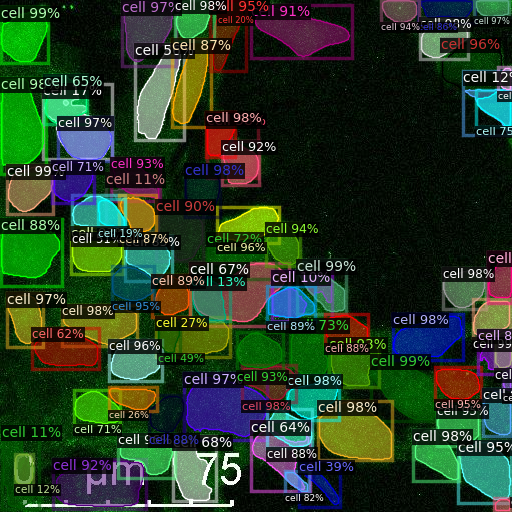

Processing checkpoint: /content/output/model_0000979.pth
[12/05 13:47:01 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000979.pth ...


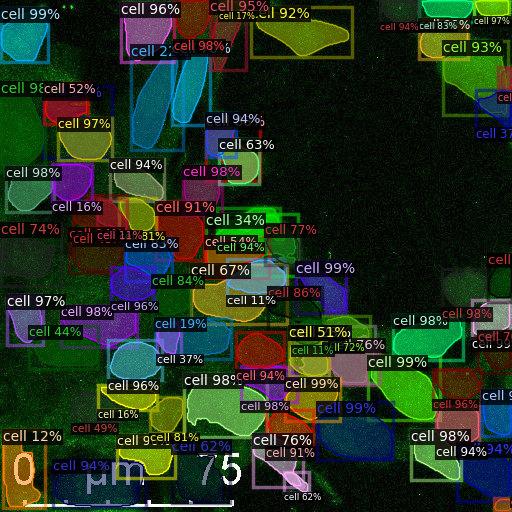

Processing checkpoint: /content/output/model_0000979.pth
[12/05 13:47:04 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000979.pth ...


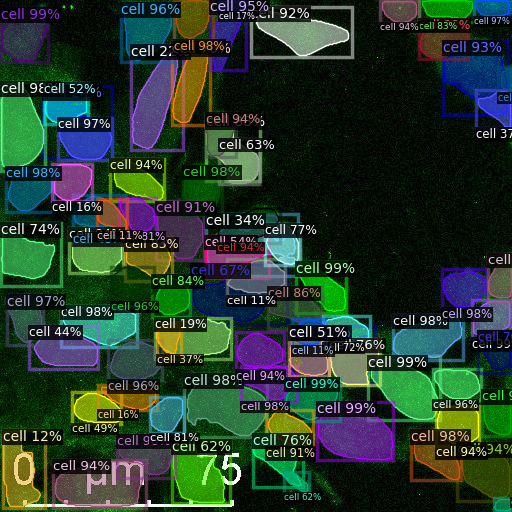

Processing checkpoint: /content/output/model_0000999.pth
[12/05 13:47:06 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000999.pth ...


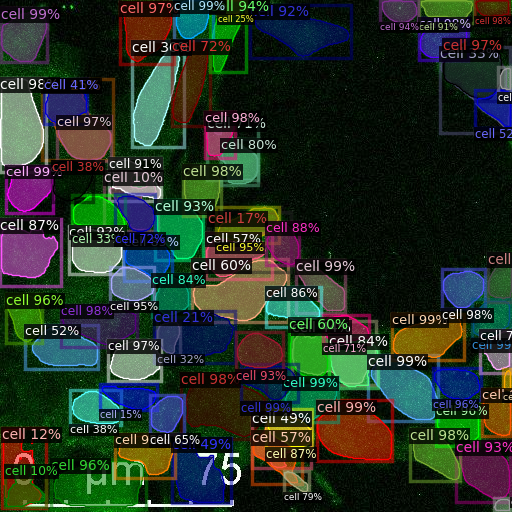

Processing checkpoint: /content/output/model_0000999.pth
[12/05 13:47:09 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000999.pth ...


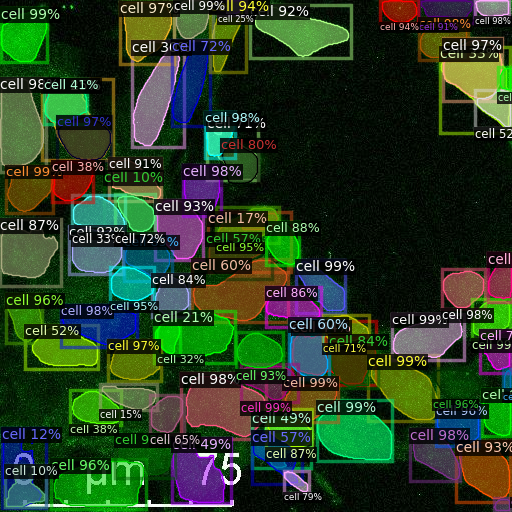

In [ ]:
import re
import glob

ckpt_dir = "/content/output"  # change if needed
# single image you want to track across epochs
image_path = "/content/test/12_jpg.rf.acece0a8f72046f8a9ff517c8c1c54b9.jpg"  # change to your image path

# output folder for visualizations
vis_out_dir = "/content/vis_by_epoch"
os.makedirs(vis_out_dir, exist_ok=True)

# utility: find checkpoint files and sort by epoch number (assumes filenames contain epoch or iter)
# Adjust the glob pattern and regex for your checkpoint naming
candidates = glob.glob(os.path.join(ckpt_dir, "*.pth")) + glob.glob(os.path.join(ckpt_dir, "model_*.pth"))
# filter out irrelevant files if any
def epoch_from_name(name):
    m = re.search(r"(\d{1,6})", os.path.basename(name))
    return int(m.group(1)) if m else -1

# pick only files that look like valid model checkpoints
ckpts = sorted([p for p in candidates if epoch_from_name(p) >= 0], key=epoch_from_name)

# fallback: if no parsed numeric name, you can force one specific file like model_final.pth
if len(ckpts) == 0:
    fallback = os.path.join(ckpt_dir, "model_final.pth")
    if os.path.exists(fallback):
        ckpts = [fallback]
    else:
        raise FileNotFoundError("No checkpoint files found in {}. Expected patterns: *.pth or model_*.pth".format(ckpt_dir))

# read image once
img = cv2.imread(image_path)
if img is None:
    raise FileNotFoundError("Couldn't read image at: " + image_path)

for ckpt in ckpts:
    print("Processing checkpoint:", ckpt)
    # update cfg weights path (reuse your cfg object)
    cfg.MODEL.WEIGHTS = ckpt
    # optionally set a very low score-thresh to see evolution:
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.1

    predictor = DefaultPredictor(cfg)
    outputs = predictor(img)  # forward pass

    v = Visualizer(img[:, :, ::-1], metadata=cells_metadata, scale=1.0, instance_mode=ColorMode.IMAGE)
    out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

    # save visualization image
    epoch_num = epoch_from_name(ckpt)
    out_path = os.path.join(vis_out_dir, f"vis_epoch_{epoch_num:04d}.jpg")
    cv2.imwrite(out_path, out.get_image()[:, :, ::-1])  # BGR for cv2

    # If you are in Colab and want to display inline:
    cv2_imshow(out.get_image()[:, :, ::-1])

In [ ]:
import imageio
imgs = []
files = sorted(glob.glob(os.path.join(vis_out_dir, "vis_epoch_*.jpg")))
for f in files:
    imgs.append(imageio.imread(f))
imageio.mimsave("/content/predictions_per_20_epochs.gif", imgs, fps=1)  # adjust fps
print("Saved GIF: /content/predictions_per_20_epochs.gif")

/tmp/ipython-input-1270723971.py:5: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  imgs.append(imageio.imread(f))


Saved GIF: /content/predictions_per_20_epochs.gif


In [ ]:
import imageio
import glob, os
import numpy as np
from PIL import Image, ImageDraw, ImageFont

imgs = []
files = sorted(glob.glob(os.path.join(vis_out_dir, "vis_epoch_*.jpg")))

for f in files:
    epoch = int(os.path.splitext(os.path.basename(f))[0].split('_')[-1])

    img = Image.open(f).convert("RGB")
    draw = ImageDraw.Draw(img)

    # Load font
    try:
        font = ImageFont.truetype("arial.ttf", 40)
    except:
        font = ImageFont.load_default()

    text = f"Epoch {epoch}"

    # NEW: get text bbox from Pillow 10+
    left, top, right, bottom = draw.textbbox((0, 0), text, font=font)
    text_w = right - left
    text_h = bottom - top

    # Background box coords
    box_x1, box_y1 = 10, 10
    box_x2, box_y2 = box_x1 + text_w + 20, box_y1 + text_h + 20

    # Draw black box behind text
    draw.rectangle((box_x1, box_y1, box_x2, box_y2), fill=(0, 0, 0))

    # Draw white text
    draw.text((box_x1 + 10, box_y1 + 10),
              text,
              fill=(255, 255, 255),
              font=font)

    imgs.append(np.array(img))

imageio.mimsave("/content/predictions_per_20_epochs.gif", imgs, fps=1)

print("Saved GIF with clear epoch labels!")


Saved GIF with clear epoch labels!


Inferencing on intermediate models (199th, 399th, 599th, 799th epochs)

[12/01 14:48:59 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000799.pth ...
WARNING [12/01 14:48:59 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[12/01 14:48:59 d2.data.datasets.coco]: Loaded 20 images in COCO format from /content/test/_annotations.coco.json


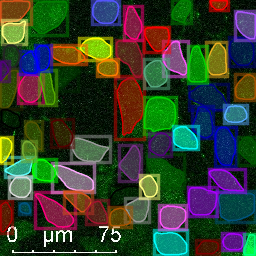

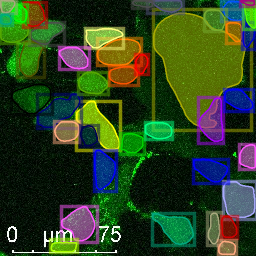

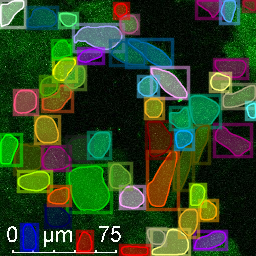

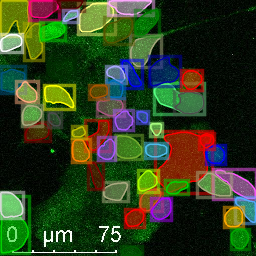

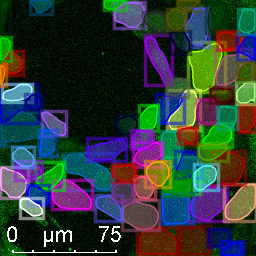

...

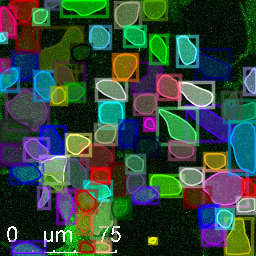

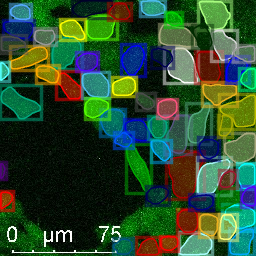

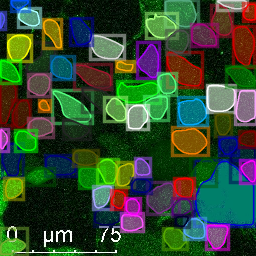

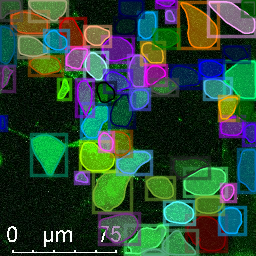

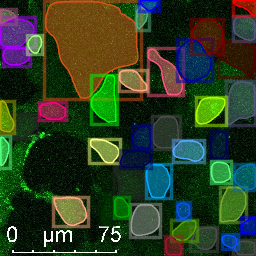

In [ ]:
# Inference + visualize only boxes + masks (no text labels)
# load trained weights & set a low threshold if you want more predictions
cfg.MODEL.WEIGHTS = "/content/output/model_0000799.pth"   # MODIFY THIS LINE
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5 # adjust as needed
predictor = DefaultPredictor(cfg)

test_dataset = DatasetCatalog.get("cells_test")

for d in test_dataset:
    img = cv2.imread(d["file_name"])
    if img is None:
        print("Could not read:", d["file_name"])
        continue

    outputs = predictor(img)
    instances = outputs.get("instances")
    if instances is None or len(instances) == 0:
        print("No predictions for:", d["file_name"])
        # still show the raw image
        cv2_imshow(img[:, :, ::-1])
        continue

    instances = instances.to("cpu")

    # extract boxes and masks if present
    masks = instances.pred_masks if instances.has("pred_masks") else None
    boxes = instances.pred_boxes if instances.has("pred_boxes") else None

    # Create a Visualizer but do NOT pass metadata (or pass None)
    v = Visualizer(img[:, :, ::-1],
                   metadata=None,
                   scale=0.5,
                   instance_mode=ColorMode.IMAGE)  # or IMAGE_BW for gray background

    # overlay_instances draws boxes and masks; labels=None disables text labels
    vis = v.overlay_instances(boxes=boxes, masks=masks, labels=None)
    vis_img = vis.get_image()[:, :, ::-1]

    cv2_imshow(vis_img)


**EVALUATION CODE**: AP and AR metrics at Diff IoU's

In [ ]:
def evaluate_checkpoint(weight_path):

    print(f"\nEvaluating: {weight_path}\n")

    cfg = get_cfg()
    cfg.merge_from_file(model_zoo.get_config_file(
        "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
    ))
    cfg.DATASETS.TEST = ("cells_test",)
    cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1
    cfg.MODEL.WEIGHTS = weight_path     # <-- load the checkpoint
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5   # irrelevant for eval AP

    # IMPORTANT: build a NEW model with these weights
    predictor = DefaultPredictor(cfg)
    model = predictor.model

    evaluator = COCOEvaluator("cells_test", cfg, False, output_dir="/content/output/")
    val_loader = build_detection_test_loader(cfg, "cells_test")

    results = inference_on_dataset(model, val_loader, evaluator)
    return results

In [ ]:
eval_final = evaluate_checkpoint("/content/output/model_final.pth")
print(eval_final)


Evaluating: /content/output/model_final.pth

[12/01 14:54:02 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_final.pth ...
[12/01 14:54:02 d2.evaluation.coco_evaluation]: Fast COCO eval is not built. Falling back to official COCO eval.
WARNING [12/01 14:54:02 d2.evaluation.coco_evaluation]: COCO Evaluator instantiated using config, this is deprecated behavior. Please pass in explicit arguments instead.
WARNING [12/01 14:54:03 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[12/01 14:54:03 d2.data.datasets.coco]: Loaded 20 images in COCO format from /content/test/_annotations.coco.json
[12/01 14:54:03 d2.data.build]: Distribution of instances among all 1 categories:
|  category  | #instances   |
|:----------:|:-------------|
|    cell    | 1236         |
|            |              |
[12/01 14:54:03 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [

For intermediate models

In [ ]:
eval_399  = evaluate_checkpoint("/content/output/model_0000399.pth")
print(eval_399)


Evaluating: /content/output/model_0000399.pth

[12/01 14:57:41 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000399.pth ...
[12/01 14:57:42 d2.evaluation.coco_evaluation]: Fast COCO eval is not built. Falling back to official COCO eval.
WARNING [12/01 14:57:42 d2.evaluation.coco_evaluation]: COCO Evaluator instantiated using config, this is deprecated behavior. Please pass in explicit arguments instead.
WARNING [12/01 14:57:42 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[12/01 14:57:42 d2.data.datasets.coco]: Loaded 20 images in COCO format from /content/test/_annotations.coco.json
[12/01 14:57:42 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[12/01 14:57:42 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerialize

In [ ]:
eval_599  = evaluate_checkpoint("/content/output/model_0000599.pth")
print(eval_599)


Evaluating: /content/output/model_0000599.pth

[12/01 14:59:31 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000599.pth ...
[12/01 14:59:31 d2.evaluation.coco_evaluation]: Fast COCO eval is not built. Falling back to official COCO eval.
WARNING [12/01 14:59:31 d2.evaluation.coco_evaluation]: COCO Evaluator instantiated using config, this is deprecated behavior. Please pass in explicit arguments instead.
WARNING [12/01 14:59:31 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[12/01 14:59:31 d2.data.datasets.coco]: Loaded 20 images in COCO format from /content/test/_annotations.coco.json
[12/01 14:59:31 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[12/01 14:59:31 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerialize

In [ ]:
eval_799  = evaluate_checkpoint("/content/output/model_0000799.pth")
print(eval_799)


Evaluating: /content/output/model_0000799.pth

[12/01 15:01:56 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/output/model_0000799.pth ...
[12/01 15:01:56 d2.evaluation.coco_evaluation]: Fast COCO eval is not built. Falling back to official COCO eval.
WARNING [12/01 15:01:56 d2.evaluation.coco_evaluation]: COCO Evaluator instantiated using config, this is deprecated behavior. Please pass in explicit arguments instead.
WARNING [12/01 15:01:56 d2.data.datasets.coco]: 
Category ids in annotations are not in [1, #categories]! We'll apply a mapping for you.

[12/01 15:01:56 d2.data.datasets.coco]: Loaded 20 images in COCO format from /content/test/_annotations.coco.json
[12/01 15:01:56 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[12/01 15:01:56 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerialize

**4 FOLD CROSS VALIDATION**

Assumes split of 32 images as 8 test, and 6*4 for 4 fold

In paper, we implemented 5 fold by split 7 test + 5*5

In [ ]:
!unzip -q "/content/CV Grp 5.v6-cross-val.coco-segmentation.zip"

Fix 'category_id'

In [ ]:
paths = [
    "/content/train/_annotations.coco.json",
    "/content/test/_annotations.coco.json"
]

# MODIFY CATEGORY ID FOR ANNOTATIONS JSON, Category IDs start from 0, NOT 1.
for path in paths:
    with open(path) as f:
        coco = json.load(f)

    # Fix ALL category_ids: 1 → 0
    for ann in coco["annotations"]:
        ann["category_id"] = 0

    # Fix the categories list
    coco["categories"] = [{"id": 0, "name": "cell"}]

    with open(path, "w") as f:
        json.dump(coco, f, indent=2)

    print("Fixed 'category_id' for:", path)


Fixed 'category_id' for: /content/train/_annotations.coco.json
Fixed 'category_id' for: /content/test/_annotations.coco.json


In [ ]:
# 1) Utilities: split COCO JSON into k folds and write per-fold JSONs
import json, os, random, shutil
from collections import defaultdict

random.seed(12345)  # reproducible

orig_json = "/content/train/_annotations.coco.json"   # your single COCO file containing the 24 images
out_dir = "/content/cv_folds"
k = 4

os.makedirs(out_dir, exist_ok=True)

with open(orig_json, "r") as f:
    coco = json.load(f)

images = coco.get("images", [])
annotations = coco.get("annotations", [])
categories = coco.get("categories", [])
licenses = coco.get("licenses", []) if "licenses" in coco else []

n = len(images)
assert n >= 24, f"Expect at least 24 image dicts, found {n}"

# shuffle and split images into k roughly equal folds
imgs = images.copy()
random.shuffle(imgs)
fold_sizes = [len(imgs) // k + (1 if i < (len(imgs) % k) else 0) for i in range(k)]

folds = []
start = 0
for size in fold_sizes:
    folds.append(imgs[start:start+size])
    start += size

# create mapping image_id -> image dict for convenience
image_id_to_image = {im["id"]: im for im in images}

# create mapping image_id -> annotations list
ann_by_image = defaultdict(list)
for ann in annotations:
    ann_by_image[ann["image_id"]].append(ann)

# Write JSONs for each fold: train = all images except fold_i, val = fold_i
for i in range(k):
    val_images = folds[i]
    val_ids = {im["id"] for im in val_images}
    train_images = [im for im in images if im["id"] not in val_ids]

    # Gather annotations
    train_anns = []
    for im in train_images:
        train_anns.extend(ann_by_image.get(im["id"], []))

    val_anns = []
    for im in val_images:
        val_anns.extend(ann_by_image.get(im["id"], []))

    # Build COCO dicts
    train_coco = {
        "images": train_images,
        "annotations": train_anns,
        "categories": categories
    }
    val_coco = {
        "images": val_images,
        "annotations": val_anns,
        "categories": categories
    }

    # Save JSONs
    fold_dir = os.path.join(out_dir, f"fold_{i}")
    os.makedirs(fold_dir, exist_ok=True)
    train_json_path = os.path.join(fold_dir, "train_annotations.json")
    val_json_path = os.path.join(fold_dir, "val_annotations.json")

    with open(train_json_path, "w") as f:
        json.dump(train_coco, f)
    with open(val_json_path, "w") as f:
        json.dump(val_coco, f)

    print(f"Fold {i}: train images = {len(train_images)}, val images = {len(val_images)}")
    print("  train json:", train_json_path)
    print("  val json:  ", val_json_path)


Fold 0: train images = 18, val images = 6
  train json: /content/cv_folds/fold_0/train_annotations.json
  val json:   /content/cv_folds/fold_0/val_annotations.json
Fold 1: train images = 18, val images = 6
  train json: /content/cv_folds/fold_1/train_annotations.json
  val json:   /content/cv_folds/fold_1/val_annotations.json
Fold 2: train images = 18, val images = 6
  train json: /content/cv_folds/fold_2/train_annotations.json
  val json:   /content/cv_folds/fold_2/val_annotations.json
Fold 3: train images = 18, val images = 6
  train json: /content/cv_folds/fold_3/train_annotations.json
  val json:   /content/cv_folds/fold_3/val_annotations.json


In [ ]:
# remove any previous registers to be safe
for name in list(DatasetCatalog.list()):
    if name.startswith("cells_fold"):
        DatasetCatalog.remove(name)
for name in list(MetadataCatalog.list()):
    if name.startswith("cells_fold"):
        MetadataCatalog.remove(name)

for i in range(k):
    fold_dir = os.path.join(out_dir, f"fold_{i}")
    train_json = os.path.join(fold_dir, "train_annotations.json")
    val_json = os.path.join(fold_dir, "val_annotations.json")
    train_images_dir = "/content/train"  # or wherever the actual image files are located (same as original)
    val_images_dir = "/content/train"    # since val images are a subset of original images folder

    # Use distinct names
    register_coco_instances(f"cells_fold{i}_train", {}, train_json, train_images_dir)
    register_coco_instances(f"cells_fold{i}_val", {}, val_json, val_images_dir)
    print("Registered:", f"cells_fold{i}_train", f"cells_fold{i}_val")


Registered: cells_fold0_train cells_fold0_val
Registered: cells_fold1_train cells_fold1_val
Registered: cells_fold2_train cells_fold2_val
Registered: cells_fold3_train cells_fold3_val


Training

In [ ]:
num_folds = k

for i in range(num_folds):
    print("=== Fold", i, "===")
    cfg = get_cfg()
    cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))

    cfg.DATASETS.TRAIN = (f"cells_fold{i}_train",)
    cfg.DATASETS.TEST = (f"cells_fold{i}_val",)   # used for evaluation after training

    cfg.DATALOADER.NUM_WORKERS = 2
    cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
    cfg.SOLVER.IMS_PER_BATCH = 2
    cfg.SOLVER.BASE_LR = 2.5e-4
    cfg.SOLVER.MAX_ITER = 1000   # adapt
    cfg.SOLVER.STEPS = []
    cfg.SOLVER.CHECKPOINT_PERIOD = 200

    cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128
    cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1             # ONE class ("cell")

    cfg.OUTPUT_DIR = f"/content/output/fold_{i}"
    os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)

    trainer = DefaultTrainer(cfg)
    trainer.resume_or_load(resume=False)
    trainer.train()

    # After training you can evaluate using COCOEvaluator (same as earlier)
    # Optionally save or move model_final.pth somewhere else
    print("Finished fold", i)


=== Fold 0 ===
[12/01 17:27:25 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
   

model_final_f10217.pkl: 178MB [00:01, 103MB/s]                           
roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}


[12/01 17:27:27 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4317.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1201 17:27:30.264000 1257 torch/fx/_symbolic_trace.py:52] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


[12/01 17:27:33 d2.utils.events]:  eta: 0:01:25  iter: 19  total_loss: 4.461  loss_cls: 0.6936  loss_box_reg: 0.6428  loss_mask: 0.6949  loss_rpn_cls: 2.087  loss_rpn_loc: 0.2432    time: 0.1059  last_time: 0.0945  data_time: 0.0124  last_data_time: 0.0045   lr: 4.9953e-06  max_mem: 1740M
[12/01 17:27:40 d2.utils.events]:  eta: 0:01:23  iter: 39  total_loss: 3.299  loss_cls: 0.6654  loss_box_reg: 0.6522  loss_mask: 0.6904  loss_rpn_cls: 1.011  loss_rpn_loc: 0.2171    time: 0.1021  last_time: 0.0824  data_time: 0.0043  last_data_time: 0.0041   lr: 9.9902e-06  max_mem: 1740M
[12/01 17:27:42 d2.utils.events]:  eta: 0:01:19  iter: 59  total_loss: 2.585  loss_cls: 0.5993  loss_box_reg: 0.6816  loss_mask: 0.6785  loss_rpn_cls: 0.4333  loss_rpn_loc: 0.1899    time: 0.0959  last_time: 0.0880  data_time: 0.0043  last_data_time: 0.0043   lr: 1.4985e-05  max_mem: 1743M
[12/01 17:27:44 d2.utils.events]:  eta: 0:01:18  iter: 79  total_loss: 2.339  loss_cls: 0.5597  loss_box_reg: 0.7053  loss_mask: 

roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}


[12/01 17:29:13 d2.engine.train_loop]: Starting training from iteration 0
[12/01 17:29:14 d2.utils.events]:  eta: 0:01:24  iter: 19  total_loss: 4.484  loss_cls: 0.6653  loss_box_reg: 0.6479  loss_mask: 0.6925  loss_rpn_cls: 2.223  loss_rpn_loc: 0.2514    time: 0.0865  last_time: 0.0881  data_time: 0.0108  last_data_time: 0.0045   lr: 4.9953e-06  max_mem: 2004M
[12/01 17:29:16 d2.utils.events]:  eta: 0:01:22  iter: 39  total_loss: 3.383  loss_cls: 0.6384  loss_box_reg: 0.6821  loss_mask: 0.6881  loss_rpn_cls: 1.087  loss_rpn_loc: 0.2296    time: 0.0860  last_time: 0.0864  data_time: 0.0045  last_data_time: 0.0042   lr: 9.9902e-06  max_mem: 2007M
[12/01 17:29:18 d2.utils.events]:  eta: 0:01:20  iter: 59  total_loss: 2.555  loss_cls: 0.5927  loss_box_reg: 0.7158  loss_mask: 0.678  loss_rpn_cls: 0.3836  loss_rpn_loc: 0.2007    time: 0.0857  last_time: 0.0843  data_time: 0.0043  last_data_time: 0.0044   lr: 1.4985e-05  max_mem: 2031M
[12/01 17:29:20 d2.utils.events]:  eta: 0:01:18  iter: 7

roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}


[12/01 17:30:45 d2.engine.train_loop]: Starting training from iteration 0
[12/01 17:30:47 d2.utils.events]:  eta: 0:01:23  iter: 19  total_loss: 4.577  loss_cls: 0.663  loss_box_reg: 0.6308  loss_mask: 0.6944  loss_rpn_cls: 2.263  loss_rpn_loc: 0.2564    time: 0.0887  last_time: 0.0975  data_time: 0.0101  last_data_time: 0.0043   lr: 4.9953e-06  max_mem: 2407M
[12/01 17:30:49 d2.utils.events]:  eta: 0:01:22  iter: 39  total_loss: 3.377  loss_cls: 0.6491  loss_box_reg: 0.6249  loss_mask: 0.6899  loss_rpn_cls: 1.068  loss_rpn_loc: 0.2314    time: 0.0874  last_time: 0.0898  data_time: 0.0045  last_data_time: 0.0045   lr: 9.9902e-06  max_mem: 2414M
[12/01 17:30:51 d2.utils.events]:  eta: 0:01:20  iter: 59  total_loss: 2.53  loss_cls: 0.6078  loss_box_reg: 0.6836  loss_mask: 0.6797  loss_rpn_cls: 0.3719  loss_rpn_loc: 0.1954    time: 0.0871  last_time: 0.0851  data_time: 0.0045  last_data_time: 0.0045   lr: 1.4985e-05  max_mem: 2415M
[12/01 17:30:53 d2.utils.events]:  eta: 0:01:18  iter: 79

roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}


[12/01 17:32:23 d2.engine.train_loop]: Starting training from iteration 0
[12/01 17:32:25 d2.utils.events]:  eta: 0:01:25  iter: 19  total_loss: 4.582  loss_cls: 0.6396  loss_box_reg: 0.6132  loss_mask: 0.695  loss_rpn_cls: 2.362  loss_rpn_loc: 0.2698    time: 0.0871  last_time: 0.0870  data_time: 0.0105  last_data_time: 0.0044   lr: 4.9953e-06  max_mem: 2743M
[12/01 17:32:27 d2.utils.events]:  eta: 0:01:22  iter: 39  total_loss: 3.248  loss_cls: 0.6298  loss_box_reg: 0.6263  loss_mask: 0.6908  loss_rpn_cls: 1.05  loss_rpn_loc: 0.2472    time: 0.0861  last_time: 0.0856  data_time: 0.0044  last_data_time: 0.0045   lr: 9.9902e-06  max_mem: 2756M
[12/01 17:32:29 d2.utils.events]:  eta: 0:01:20  iter: 59  total_loss: 2.625  loss_cls: 0.6014  loss_box_reg: 0.694  loss_mask: 0.6811  loss_rpn_cls: 0.4651  loss_rpn_loc: 0.202    time: 0.0861  last_time: 0.0846  data_time: 0.0044  last_data_time: 0.0045   lr: 1.4985e-05  max_mem: 2756M
[12/01 17:32:30 d2.utils.events]:  eta: 0:01:18  iter: 79  